<a href="https://colab.research.google.com/github/Pedro-Veiga0/HipMoS4C/blob/main/TestingAnomalib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import timm
all_densenet_models = timm.list_models('*dino*')
print(all_densenet_models)

['vit_7b_patch16_dinov3', 'vit_base_patch14_dinov2', 'vit_base_patch14_reg4_dinov2', 'vit_base_patch16_dinov3', 'vit_base_patch16_dinov3_qkvb', 'vit_giant_patch14_dinov2', 'vit_giant_patch14_reg4_dinov2', 'vit_huge_plus_patch16_dinov3', 'vit_huge_plus_patch16_dinov3_qkvb', 'vit_large_patch14_dinov2', 'vit_large_patch14_reg4_dinov2', 'vit_large_patch16_dinov3', 'vit_large_patch16_dinov3_qkvb', 'vit_small_patch14_dinov2', 'vit_small_patch14_reg4_dinov2', 'vit_small_patch16_dinov3', 'vit_small_patch16_dinov3_qkvb', 'vit_small_plus_patch16_dinov3', 'vit_small_plus_patch16_dinov3_qkvb', 'vit_tiny_patch16_dinov3_qkvb']


In [ ]:
# Install Anomalib with full dependencies
!pip install --quiet "anomalib[full]"

# Testing Library

In [ ]:
from pathlib import Path
from google.colab import drive
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Padim

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Point to the parent folder containing your MVTec category folders
# (e.g., if your bottle images are in /content/drive/MyDrive/anomalib_datasets/MVTecAD/bottle)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")

# 3. Configure the DataModule with your Drive path
category = "bottle"
datamodule = MVTecAD(
    root=drive_dataset_root,
    category=category,
    train_batch_size=16,
    eval_batch_size=16,
    num_workers=2,
)

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


In [ ]:
# Initialize PaDiM model
model = Padim(
    backbone="resnet18",
    layers=["layer1", "layer2"],
    n_features=100,
)

# Engine configured for GPU acceleration
engine = Engine(
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
)

In [ ]:
from anomalib.models import Supersimplenet

model = Supersimplenet()

engine = Engine(
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
from anomalib.models import Patchcore

model = Patchcore(backbone='wide_resnet50_2', layers=['layer1', 'layer2', 'layer3'], coreset_sampling_ratio=0.1)
engine = Engine(
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
)

In [ ]:
from anomalib.models import Dinomaly

model = Dinomaly(
    encoder_name="vit_large_patch14_reg4_dinov2",
    decoder_depth=12,
    bottleneck_dropout=0.1,
)
engine = Engine(
    max_epochs=10,
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
from anomalib.models.image.anomaly_dino.lightning_model import AnomalyDINO

model = AnomalyDINO(
    num_neighbours=1,
    encoder_name="vit_small_patch14_dinov2",
    masking=False,
    coreset_subsampling=False,
    sampling_ratio=0.1,
)
# model.name = "AnomalyDINOModel"

engine = Engine(
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
)

In [ ]:
# Fit Gaussian distributions on normal training samples
print("Starting training...")
engine.fit(datamodule=datamodule, model=model)

# Run evaluation on test split
test_results = engine.test(datamodule=datamodule, model=model)
metrics_dict = test_results[0]

print("\n========== MODEL EVALUATION SCORES ==========")
print(f"Image-level AUROC : {metrics_dict.get('image_AUROC', 'N/A'):.4f}")
print(f"Pixel-level AUROC : {metrics_dict.get('pixel_AUROC', 'N/A'):.4f}")
print(f"Image F1-Score    : {metrics_dict.get('image_F1Score', 'N/A'):.4f}")
print(f"Pixel F1-Score    : {metrics_dict.get('pixel_F1Score', 'N/A'):.4f}")
print("=============================================\n")

In [ ]:
import matplotlib.pyplot as plt

# Generate batch predictions
predictions = engine.predict(
    datamodule=datamodule,
    model=model,
    return_predictions=True,
)

sample_batch = predictions[0]
num_samples = min(4, len(sample_batch["image"]))

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
for i in range(num_samples):
    img = sample_batch["image"][i].permute(1, 2, 0).cpu().numpy()
    gt_mask = sample_batch["pred_mask"][i].cpu().numpy()
    anomaly_map = sample_batch["anomaly_map"][i].cpu().numpy()

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(img)
    axes[i, 2].imshow(anomaly_map, cmap="jet", alpha=0.5)
    axes[i, 2].set_title("Anomaly Heatmap Overlay")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from anomalib.deploy import ExportType
drive_experiments_dir = Path("/content/drive/MyDrive/anomalib_experiments/bottle_anomalydino")
drive_experiments_dir.mkdir(parents=True, exist_ok=True)

# 6. Export for standalone deployment (Torch .pt and OpenVINO)
engine.export(
    model=model,
    export_type=ExportType.TORCH,
    export_root=drive_experiments_dir / "exported_models",
)
engine.export(
    model=model,
    export_type=ExportType.OPENVINO,
    export_root=drive_experiments_dir / "exported_models",
)

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from google.colab import drive
from anomalib.deploy import TorchInferencer
import os
import numpy as np

drive.mount('/content/drive')
model_path = Path("/content/drive/MyDrive/anomalib_experiments/bottle_anomalydino/exported_models/weights/torch/model.pt")

# Set environment variable to trust remote code for model loading
os.environ["TRUST_REMOTE_CODE"] = "1"

# Initialize standalone inferencer
inferencer = TorchInferencer(path=model_path, device="cuda")

# Run inference on a test image file
test_img_path = "/content/drive/MyDrive/anomalib_datasets/MVTecAD/bottle/test/broken_small/009.png"
predictions = inferencer.predict(image=test_img_path)

# Extract prediction results
anomaly_score = predictions.pred_score.item()
anomaly_map = predictions.anomaly_map.squeeze(0).cpu().numpy()

# Get original image, squeeze batch, and permute to (H, W, C)
raw_img = predictions.image.squeeze(0).permute(1, 2, 0).cpu().numpy()

# Denormalize image for visualization if it has been normalized (standard for Anomalib models)
img_min, img_max = raw_img.min(), raw_img.max()
original_image = (raw_img - img_min) / (img_max - img_min) if img_max > img_min else raw_img

print(f"Anomaly Score: {anomaly_score:.4f}")

# Plot Original and Heatmap side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Subplot 1: Original Image
axes[0].imshow(original_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

# Subplot 2: Heatmap Overlay
axes[1].imshow(original_image)
axes[1].imshow(anomaly_map, cmap="jet", alpha=0.5)
axes[1].set_title(f"Anomaly Heatmap (Score: {anomaly_score:.2f})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print(f"\n{predictions.pred_score}\n{predictions.pred_label}\n{predictions.pred_mask}")


tensor([[0.7366]], device='cuda:0')
tensor([True], device='cuda:0')
Mask([[[False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       ...,
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False]]], device='cuda:0')


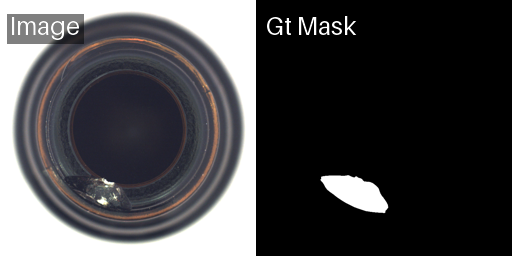

In [ ]:
from anomalib.visualization.image.item_visualizer import visualize_image_item
from anomalib.data import ImageItem
from PIL import Image
import torch
from torchvision.io import read_image

# Create sample data
image_path = "/content/drive/MyDrive/anomalib_datasets/MVTecAD/bottle/test/broken_small/009.png"
mask_path = "/content/drive/MyDrive/anomalib_datasets/MVTecAD/bottle/ground_truth/broken_small/009_mask.png"
image = read_image(image_path)
mask = read_image(mask_path)

# Create an ImageItem
item = ImageItem(
    image_path=image_path,
    mask_path=mask_path,
    image=image,
    gt_mask=mask,
)

# Generate visualization
vis_result = visualize_image_item(item, fields=["image", "gt_mask"])
vis_result

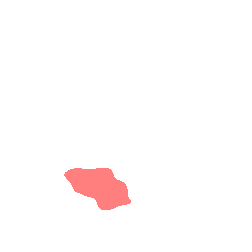

In [ ]:
import torch
from anomalib.visualization.image.functional import visualize_gt_mask, visualize_pred_mask

# Create sample mask
mask = predictions.pred_mask

# Visualize prediction mask
pred_vis = visualize_pred_mask(
    mask,
    mode="fill",              # Fill mask regions
    color=(255, 0, 0),        # Red color
    alpha=0.5,                # Opacity
)
pred_vis

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from torchvision.io import read_image
import torch

# 1. Prepare Ground Truth Mask
gt_mask_path = "/content/drive/MyDrive/anomalib_datasets/MVTecAD/bottle/ground_truth/broken_small/009_mask.png"
gt_mask = read_image(gt_mask_path).squeeze().cpu().numpy()

# 2. Prepare Predicted Mask
# 'predictions.pred_mask' is a boolean tensor from our previous inference
pred_mask = predictions.pred_mask.squeeze().cpu().numpy()

# 3. Create the side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Subplot 1: Ground Truth
axes[0].imshow(gt_mask, cmap="gray")
axes[0].set_title("Ground Truth Mask", fontsize=14)
axes[0].axis("off")

# Subplot 2: Predicted Mask
axes[1].imshow(pred_mask, cmap="gray")
axes[1].set_title("Predicted Mask", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
sample_batch

# PatchCore Paper

In [ ]:
from pathlib import Path
import gc
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore

# 1. Mount Google Drive
drive.mount('/content/drive')
dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")

# 2. All 15 MVTec AD categories
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


In [ ]:
# 3. Experiment storage
results_list = []

for category in ALL_CATEGORIES:
    print(f"\n================ Running PatchCore on: {category.upper()} ================")

    # Free cached memory before each run
    gc.collect()
    torch.cuda.empty_cache()

    # DataModule matching paper resolution (224x224)
    datamodule = MVTecAD(
        root=dataset_root,
        category=category,
        train_batch_size=16,
        eval_batch_size=16,      # Small eval batch to fit distance matrices in VRAM
        num_workers=2,
    )

    # PatchCore configured to match Roth et al. (CVPR 2022)
    model = Patchcore(
        backbone="wide_resnet50_2",             # Paper baseline backbone
        layers=["layer2", "layer3"],             # Multi-scale feature levels
        coreset_sampling_ratio=0.1,
        precision='float16',             # 1% coreset for GPU memory efficiency
        num_neighbors=9,                         # k=9 nearest neighbors
    )

    # Engine requesting both Image AUROC and Pixel AUROC + AUPRO
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    # Fit feature bank & evaluate test split
    engine.fit(datamodule=datamodule, model=model)
    test_scores = engine.test(datamodule=datamodule, model=model)[0]

    # Log metrics
    results_list.append({
        "Category": category,
        "Type": "Object" if category in OBJECT_CATEGORIES else "Texture",
        "Image_AUROC": test_scores.get("image_AUROC", 0.0),
        "Pixel_AUROC": test_scores.get("pixel_AUROC", 0.0),
        "Pixel_AUPRO": test_scores.get("pixel_AUPRO", 0.0),
    })

In [ ]:
# 4. Aggregate and Display Results
df = pd.DataFrame(results_list)

# Calculate summary rows
mean_all = df[["Image_AUROC", "Pixel_AUROC", "Pixel_AUPRO"]].mean().to_dict()
mean_all["Category"] = "OVERALL MEAN"
mean_all["Type"] = "Summary"

mean_objects = df[df["Type"] == "Object"][["Image_AUROC", "Pixel_AUROC", "Pixel_AUPRO"]].mean().to_dict()
mean_objects["Category"] = "OBJECTS MEAN"
mean_objects["Type"] = "Summary"

mean_textures = df[df["Type"] == "Texture"][["Image_AUROC", "Pixel_AUROC", "Pixel_AUPRO"]].mean().to_dict()
mean_textures["Category"] = "TEXTURES MEAN"
mean_textures["Type"] = "Summary"

summary_df = pd.concat([df, pd.DataFrame([mean_objects, mean_textures, mean_all])], ignore_index=True)

# Format as percentages
print("\n" + "="*60 + " BENCHMARK RESULTS " + "="*60)
display_df = summary_df.copy()
for col in ["Image_AUROC", "Pixel_AUROC", "Pixel_AUPRO"]:
    display_df[col] = (display_df[col] * 100).round(2).astype(str) + "%"

print(display_df.to_string(index=False))


============================================================ BENCHMARK RESULTS ============================================================
     Category    Type Image_AUROC Pixel_AUROC Pixel_AUPRO
       bottle  Object      100.0%      98.56%        0.0%
        cable  Object       98.7%      98.46%        0.0%
      capsule  Object      99.28%       99.0%        0.0%
     hazelnut  Object      100.0%      98.82%        0.0%
    metal_nut  Object       99.8%      98.69%        0.0%
         pill  Object       94.2%      98.12%        0.0%
        screw  Object      97.08%      98.95%        0.0%
   toothbrush  Object      91.67%      98.89%        0.0%
   transistor  Object       99.0%      97.19%        0.0%
       zipper  Object       97.6%      98.15%        0.0%
       carpet Texture      98.64%      99.07%        0.0%
         grid Texture      98.91%      98.25%        0.0%
      leather Texture      100.0%      99.23%        0.0%
         tile Texture      100.0%      95.52%  

In [ ]:
# Save to Drive as CSV
summary_df.to_csv("/content/drive/MyDrive/anomalib_experiments/patchcore_mvtec_replication.csv", index=False)

# PatchCore with ViT backbone

BACKBONE = "vit_7b_patch16_dinov3"

*   CATEGORY = "bottle"
*   CORESET_RATIO = 0.1
*   CHOSEN_LAYERS = ["blocks.2", "blocks.16", "blocks.37"]

MODEL EVALUATION SCORES

*   Image-level AUROC : 1.0000
*   Pixel-level AUROC : 0.9901
*   Image F1-Score    : 0.9920
*   Pixel F1-Score    : 0.7815

In [ ]:
from pathlib import Path
from google.colab import drive
import torch
import pandas as pd
import datetime

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Padim

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Point to the parent folder containing your MVTec category folders
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")

# 3. Configure the DataModule
# Note: In some versions of Anomalib, image resolution is set via image_size=(h, w)
category = "bottle"
datamodule = MVTecAD(
    root=drive_dataset_root,
    category=category,
    train_batch_size=32,
    eval_batch_size=32,
    num_workers=2,
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import timm
print(timm.create_model("vit_7b_patch16_dinov3", features_only=True).feature_info.module_name())

['blocks.37', 'blocks.38', 'blocks.39']


In [ ]:
# 2. Experiment Configurations
CATEGORY = "bottle"
BACKBONE = "vit_7b_patch16_dinov3"  # or "vit_small_patch14_dinov2"
CORESET_RATIO = 0.1
KNN_NEIGHBORS = 9
CHOSEN_LAYERS = ["blocks.2", "blocks.16", "blocks.37"]

In [ ]:
from anomalib.models import Patchcore
from anomalib.pre_processing import PreProcessor
from torchvision.transforms.v2 import Compose, Normalize, Resize
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, AUPRO, AUPIMO
import pandas as pd

# Create metrics
# metrics = [
#     AUROC(fields=["pred_score", "gt_label"]),
#     F1Score(fields=["pred_label", "gt_label"]),
#     AUPIMO(),
#     AUPRO(fields=["pred_score", "gt_label"], fpr_limit=0.3),
# ]

# Create evaluator with metrics
# evaluator = Evaluator(test_metrics=metrics)

# transform = Compose([
#     Resize(size=(224, 224)),
# ])

# pre_processor = PreProcessor(transform=transform)

model = Patchcore(
    backbone=BACKBONE,
    layers=CHOSEN_LAYERS,  # Multi-scale feature levels
    coreset_sampling_ratio=CORESET_RATIO,
    # precision='float16',             # 1% coreset for GPU memory efficiency
    num_neighbors=KNN_NEIGHBORS,                         # k=9 nearest neighbors
    # pre_processor=pre_processor,
    # evaluator=evaluator,
    )

engine = Engine(
    default_root_dir="./results",
    accelerator="gpu",
    devices=1,
    enable_progress_bar=False,
)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


In [ ]:
# Fit Gaussian distributions on normal training samples
print("Starting training...")
engine.fit(datamodule=datamodule, model=model)

# Run evaluation on test split
test_results = engine.test(datamodule=datamodule, model=model)
metrics_dict = test_results[0]

print("\n========== MODEL EVALUATION SCORES ==========")
print(f"Image-level AUROC : {metrics_dict.get('image_AUROC', 'N/A'):.4f}")
print(f"Pixel-level AUROC : {metrics_dict.get('pixel_AUROC', 'N/A'):.4f}")
print(f"Image F1-Score    : {metrics_dict.get('image_F1Score', 'N/A'):.4f}")
print(f"Pixel F1-Score    : {metrics_dict.get('pixel_F1Score', 'N/A'):.4f}")
print("=============================================\n")

In [ ]:
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

new_record = {
    "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "Category": CATEGORY,
    "Backbone": BACKBONE,
    "Layers_Used": ", ".join(CHOSEN_LAYERS),
    "Num_Layers": len(CHOSEN_LAYERS),
    "Coreset_Ratio": CORESET_RATIO,
    "KNN": KNN_NEIGHBORS,
    "Image_AUROC": round(float(test_results[0].get("image_AUROC", 0.0)), 4),
    "Pixel_AUROC": round(float(test_results[0].get("pixel_AUROC", 0.0)), 4),
    "Image_F1Score": round(float(test_results[0].get("image_F1Score", 0.0)), 4),
    "Pixel_F1Score": round(float(test_results[0].get("pixel_F1Score", 0.0)), 4),
}

new_df = pd.DataFrame([new_record])

# 8. Append to Persistent Excel Spreadsheet
if excel_log_path.exists():
    existing_df = pd.read_excel(excel_log_path)
    updated_df = pd.concat([existing_df, new_df], ignore_index=True)
else:
    updated_df = new_df

updated_df.to_excel(excel_log_path, index=False)
print(f"\nExperiment successfully logged to: {excel_log_path}")

# Display current logged history
print("\n========== EXPERIMENT LOG HISTORY ==========")
print(updated_df.to_string(index=False))


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments.xlsx

========== EXPERIMENT LOG HISTORY ==========
          Timestamp Category                 Backbone                   Layers_Used  Num_Layers  Coreset_Ratio  KNN  Image_AUROC  Pixel_AUROC  Image_F1Score  Pixel_F1Score
2026-09-02 14:21:37   bottle vit_small_patch16_dinov3 blocks.2, blocks.6, blocks.10           3            0.1    9          1.0       0.9874          0.992         0.7505


In [ ]:
test_results

[{'image_AUROC': 1.0,
  'image_F1Score': 0.9919999837875366,
  'pixel_AUROC': 0.9768165349960327,
  'pixel_F1Score': 0.6865167617797852}]

In [ ]:
import matplotlib.pyplot as plt

# Generate batch predictions
predictions = engine.predict(
    datamodule=datamodule,
    model=model,
    return_predictions=True,
)

sample_batch = predictions[0]
num_samples = min(4, len(sample_batch["image"]))

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
for i in range(num_samples):
    img = sample_batch["image"][i].permute(1, 2, 0).cpu().numpy()
    gt_mask = sample_batch["pred_mask"][i].cpu().numpy()
    anomaly_map = sample_batch["anomaly_map"][i].cpu().numpy()

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(img)
    axes[i, 2].imshow(anomaly_map, cmap="jet", alpha=0.5)
    axes[i, 2].set_title("Anomaly Heatmap Overlay")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

# Testing different backbones and layers in PatchCore

In [ ]:
import sys
import gc
import datetime
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.pre_processing import PreProcessor
from torchvision.transforms.v2 import Compose, Normalize, Resize

# transform = Compose([
#     Resize(size=(224, 224)),
# ])

# pre_processor = PreProcessor(transform=transform)

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
CATEGORY = "bottle"
BACKBONE = "vit_base_patch16_dinov3"  # or "vit_small_patch14_dinov2"
CORESET_RATIO = [0.01, 0.25]
KNN_NEIGHBORS = 9

layer_experiments = [
    ["blocks.2", "blocks.6", "blocks.10"],
    ["blocks.1", "blocks.5", "blocks.9"],
    ["blocks.3", "blocks.7", "blocks.11"],
    ["blocks.1", "blocks.6", "blocks.11"],
    ["blocks.2", "blocks.5", "blocks.8"],
]


# 3. DataModule Configuration
datamodule = MVTecAD(
    root=drive_dataset_root,
    category=CATEGORY,
    train_batch_size=16,
    eval_batch_size=16,
    num_workers=2,
)

for coreset in CORESET_RATIO:
  for layers in layer_experiments:
    gc.collect()
    torch.cuda.empty_cache()
    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=coreset,
        num_neighbors=KNN_NEIGHBORS,
        # pre_processor=pre_processor,
    )

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    # 6. Fit and Test
    print(f"Fitting PatchCore with {BACKBONE} on layers {layers}...")
    engine.fit(datamodule=datamodule, model=model)

    print("Running test evaluation...")
    test_results = engine.test(datamodule=datamodule, model=model)[0]

    # 7. Format Result Entry
    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Category": CATEGORY,
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": coreset,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(test_results.get("image_AUROC", 0.0)), 4),
        "Pixel_AUROC": round(float(test_results.get("pixel_AUROC", 0.0)), 4),
        "Image_F1Score": round(float(test_results.get("image_F1Score", 0.0)), 4),
        "Pixel_F1Score": round(float(test_results.get("pixel_F1Score", 0.0)), 4),
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

    # Display current logged history
    print("\n========== EXPERIMENT LOG HISTORY ==========")
    print(updated_df.to_string(index=False))

In [ ]:
import ast
import re
from pathlib import Path
from google.colab import drive
import pandas as pd

# 1. Mount Google Drive and load file
drive.mount('/content/drive')
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments.xlsx")

if not excel_log_path.exists():
    raise FileNotFoundError(f"File not found at: {excel_log_path}")

df = pd.read_excel(excel_log_path)
print(f"Loaded {len(df)} total rows.")

# 2. Drop the 'Num_Layers' column
if "Num_Layers" in df.columns:
    df = df.drop(columns=["Num_Layers"])
    print("✓ Successfully dropped 'Num_Layers' column.")

# 3. Unpack and correct 'Coreset_Ratio' lists
def parse_list_entry(val):
    """Safely extracts a Python list from a string representation."""
    if isinstance(val, (list, tuple)):
        return list(val)
    if isinstance(val, str) and ("[" in val or "," in val):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, (list, tuple)):
                return list(parsed)
        except Exception:
            numbers = re.findall(r"[-+]?(?:\d*\.\d+|\d+)", val)
            if numbers:
                return [float(x) for x in numbers]
    return None

# Find all rows where a list was stored instead of a float
list_mask = df["Coreset_Ratio"].apply(lambda x: parse_list_entry(x) is not None)
corrupted_indices = df[list_mask].index.tolist()

if corrupted_indices:
    print(f"\nFound {len(corrupted_indices)} rows with list entries in 'Coreset_Ratio'. Fixing values...")

    # Iterate through consecutive blocks of corrupted entries
    current_list = None
    list_cycle_idx = 0

    for idx in corrupted_indices:
        raw_val = df.loc[idx, "Coreset_Ratio"]
        parsed = parse_list_entry(raw_val)

        # Reset cycle index if a new distinct list appears
        if parsed != current_list:
            current_list = parsed
            list_cycle_idx = 0

        # Assign the sequential element from the list
        assigned_val = current_list[list_cycle_idx % len(current_list)]
        df.loc[idx, "Coreset_Ratio"] = float(assigned_val)
        list_cycle_idx += 1

    print("✓ Successfully restored individual scalar Coreset_Ratio values.")
else:
    print("No list strings detected in 'Coreset_Ratio'. Values are already scalars.")

# 4. Safely deduplicate now that Coreset_Ratio has distinct values
config_cols = ["Category", "Backbone", "Layers_Used", "Coreset_Ratio", "KNN"]
available_keys = [c for c in config_cols if c in df.columns]

before_dedup = len(df)
df = df.drop_duplicates(subset=available_keys, keep="last")
print(f"✓ Deduplication complete: {before_dedup} rows -> {len(df)} distinct experiments preserved.")

# 5. Save back to Excel with auto-fitted columns
with pd.ExcelWriter(excel_log_path, engine="openpyxl") as writer:
    df.to_excel(writer, index=False, sheet_name="Experiments")
    worksheet = writer.sheets["Experiments"]

    for col in worksheet.columns:
        max_len = max(len(str(cell.value or "")) for cell in col)
        col_letter = col[0].column_letter
        worksheet.column_dimensions[col_letter].width = max(max_len + 4, 12)

print(f"\nSaved cleaned and repaired file to: {excel_log_path}")

# 6. Preview the cleaned table
print("\n========== REPAIRED EXPERIMENT LOG ==========")
print(df.to_string(index=False))

# Testing different backbones and layers in PatchCore V2

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.pre_processing import PreProcessor
from torchvision.transforms.v2 import Compose, Normalize, Resize

# transform = Compose([
#     Resize(size=(224, 224)),
# ])

# pre_processor = PreProcessor(transform=transform)

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
# All 15 MVTec AD categories
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"  # or "vit_small_patch14_dinov2"
CORESET_RATIO = 0.25
KNN_NEIGHBORS = [1, 5, 15]

# layer_experiments = ["blocks.0", "blocks.1", "blocks.2", "blocks.3", "blocks.4", "blocks.5", "blocks.6", "blocks.7", "blocks.8", "blocks.9", "blocks.10", "blocks.11"]
layer_experiments = ["blocks.5", "blocks.8"]

for category in ALL_CATEGORIES:
  for knn in KNN_NEIGHBORS:
    gc.collect()
    torch.cuda.empty_cache()

# 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=16,
        eval_batch_size=16,
        num_workers=2,
    )
    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layer_experiments, # Changed to pass layers as a list
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=knn,
        # pre_processor=pre_processor,
    )

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"Fitting PatchCore with {BACKBONE} on layers {layer_experiments}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration} seconds ({training_duration / 60:.2f} minutes)")

    print("Running test evaluation...")
    test_results = engine.test(datamodule=datamodule, model=model)[0]

    # 7. Format Result Entry
    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layer_experiments), # Changed to join a list with a single element
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": knn,
        "Image_AUROC": round(float(test_results.get("image_AUROC", 0.0)), 4),
        "Pixel_AUROC": round(float(test_results.get("pixel_AUROC", 0.0)), 4),
        "Image_F1Score": round(float(test_results.get("image_F1Score", 0.0)), 4),
        "Pixel_F1Score": round(float(test_results.get("pixel_F1Score", 0.0)), 4),
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

    # Display current logged history
    print("\n========== EXPERIMENT LOG HISTORY ==========")
    print(updated_df.to_string(index=False))

In [ ]:
import ast
import re
from pathlib import Path
from google.colab import drive
import pandas as pd

# 1. Mount Google Drive and load file
drive.mount('/content/drive')
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")

if not excel_log_path.exists():
    raise FileNotFoundError(f"File not found at: {excel_log_path}")

df = pd.read_excel(excel_log_path)
print(f"Loaded {len(df)} total rows.")

# 2. Drop the 'Num_Layers' column
if "Num_Layers" in df.columns:
    df = df.drop(columns=["Num_Layers"])
    print("✓ Successfully dropped 'Num_Layers' column.")

# 3. Unpack and correct 'Coreset_Ratio' lists
def parse_list_entry(val):
    """Safely extracts a Python list from a string representation."""
    if isinstance(val, (list, tuple)):
        return list(val)
    if isinstance(val, str) and ("[" in val or "," in val):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, (list, tuple)):
                return list(parsed)
        except Exception:
            numbers = re.findall(r"[-+]?(?:\d*\.\d+|\d+)", val)
            if numbers:
                return [float(x) for x in numbers]
    return None

# Find all rows where a list was stored instead of a float
list_mask = df["Coreset_Ratio"].apply(lambda x: parse_list_entry(x) is not None)
corrupted_indices = df[list_mask].index.tolist()

if corrupted_indices:
    print(f"\nFound {len(corrupted_indices)} rows with list entries in 'Coreset_Ratio'. Fixing values...")

    # Iterate through consecutive blocks of corrupted entries
    current_list = None
    list_cycle_idx = 0

    for idx in corrupted_indices:
        raw_val = df.loc[idx, "Coreset_Ratio"]
        parsed = parse_list_entry(raw_val)

        # Reset cycle index if a new distinct list appears
        if parsed != current_list:
            current_list = parsed
            list_cycle_idx = 0

        # Assign the sequential element from the list
        assigned_val = current_list[list_cycle_idx % len(current_list)]
        df.loc[idx, "Coreset_Ratio"] = float(assigned_val)
        list_cycle_idx += 1

    print("✓ Successfully restored individual scalar Coreset_Ratio values.")
else:
    print("No list strings detected in 'Coreset_Ratio'. Values are already scalars.")

# 4. Safely deduplicate now that Coreset_Ratio has distinct values
config_cols = ["Category", "Backbone", "Layers_Used", "Coreset_Ratio", "KNN"]
available_keys = [c for c in config_cols if c in df.columns]

before_dedup = len(df)
df = df.drop_duplicates(subset=available_keys, keep="last")
print(f"✓ Deduplication complete: {before_dedup} rows -> {len(df)} distinct experiments preserved.")

# 5. Save back to Excel with auto-fitted columns
with pd.ExcelWriter(excel_log_path, engine="openpyxl") as writer:
    df.to_excel(writer, index=False, sheet_name="Experiments")
    worksheet = writer.sheets["Experiments"]

    for col in worksheet.columns:
        max_len = max(len(str(cell.value or "")) for cell in col)
        col_letter = col[0].column_letter
        worksheet.column_dimensions[col_letter].width = max(max_len + 4, 12)

print(f"\nSaved cleaned and repaired file to: {excel_log_path}")

# 6. Preview the cleaned table
print("\n========== REPAIRED EXPERIMENT LOG ==========")
print(df.to_string(index=False))

# Data Visualization

Mounted at /content/drive


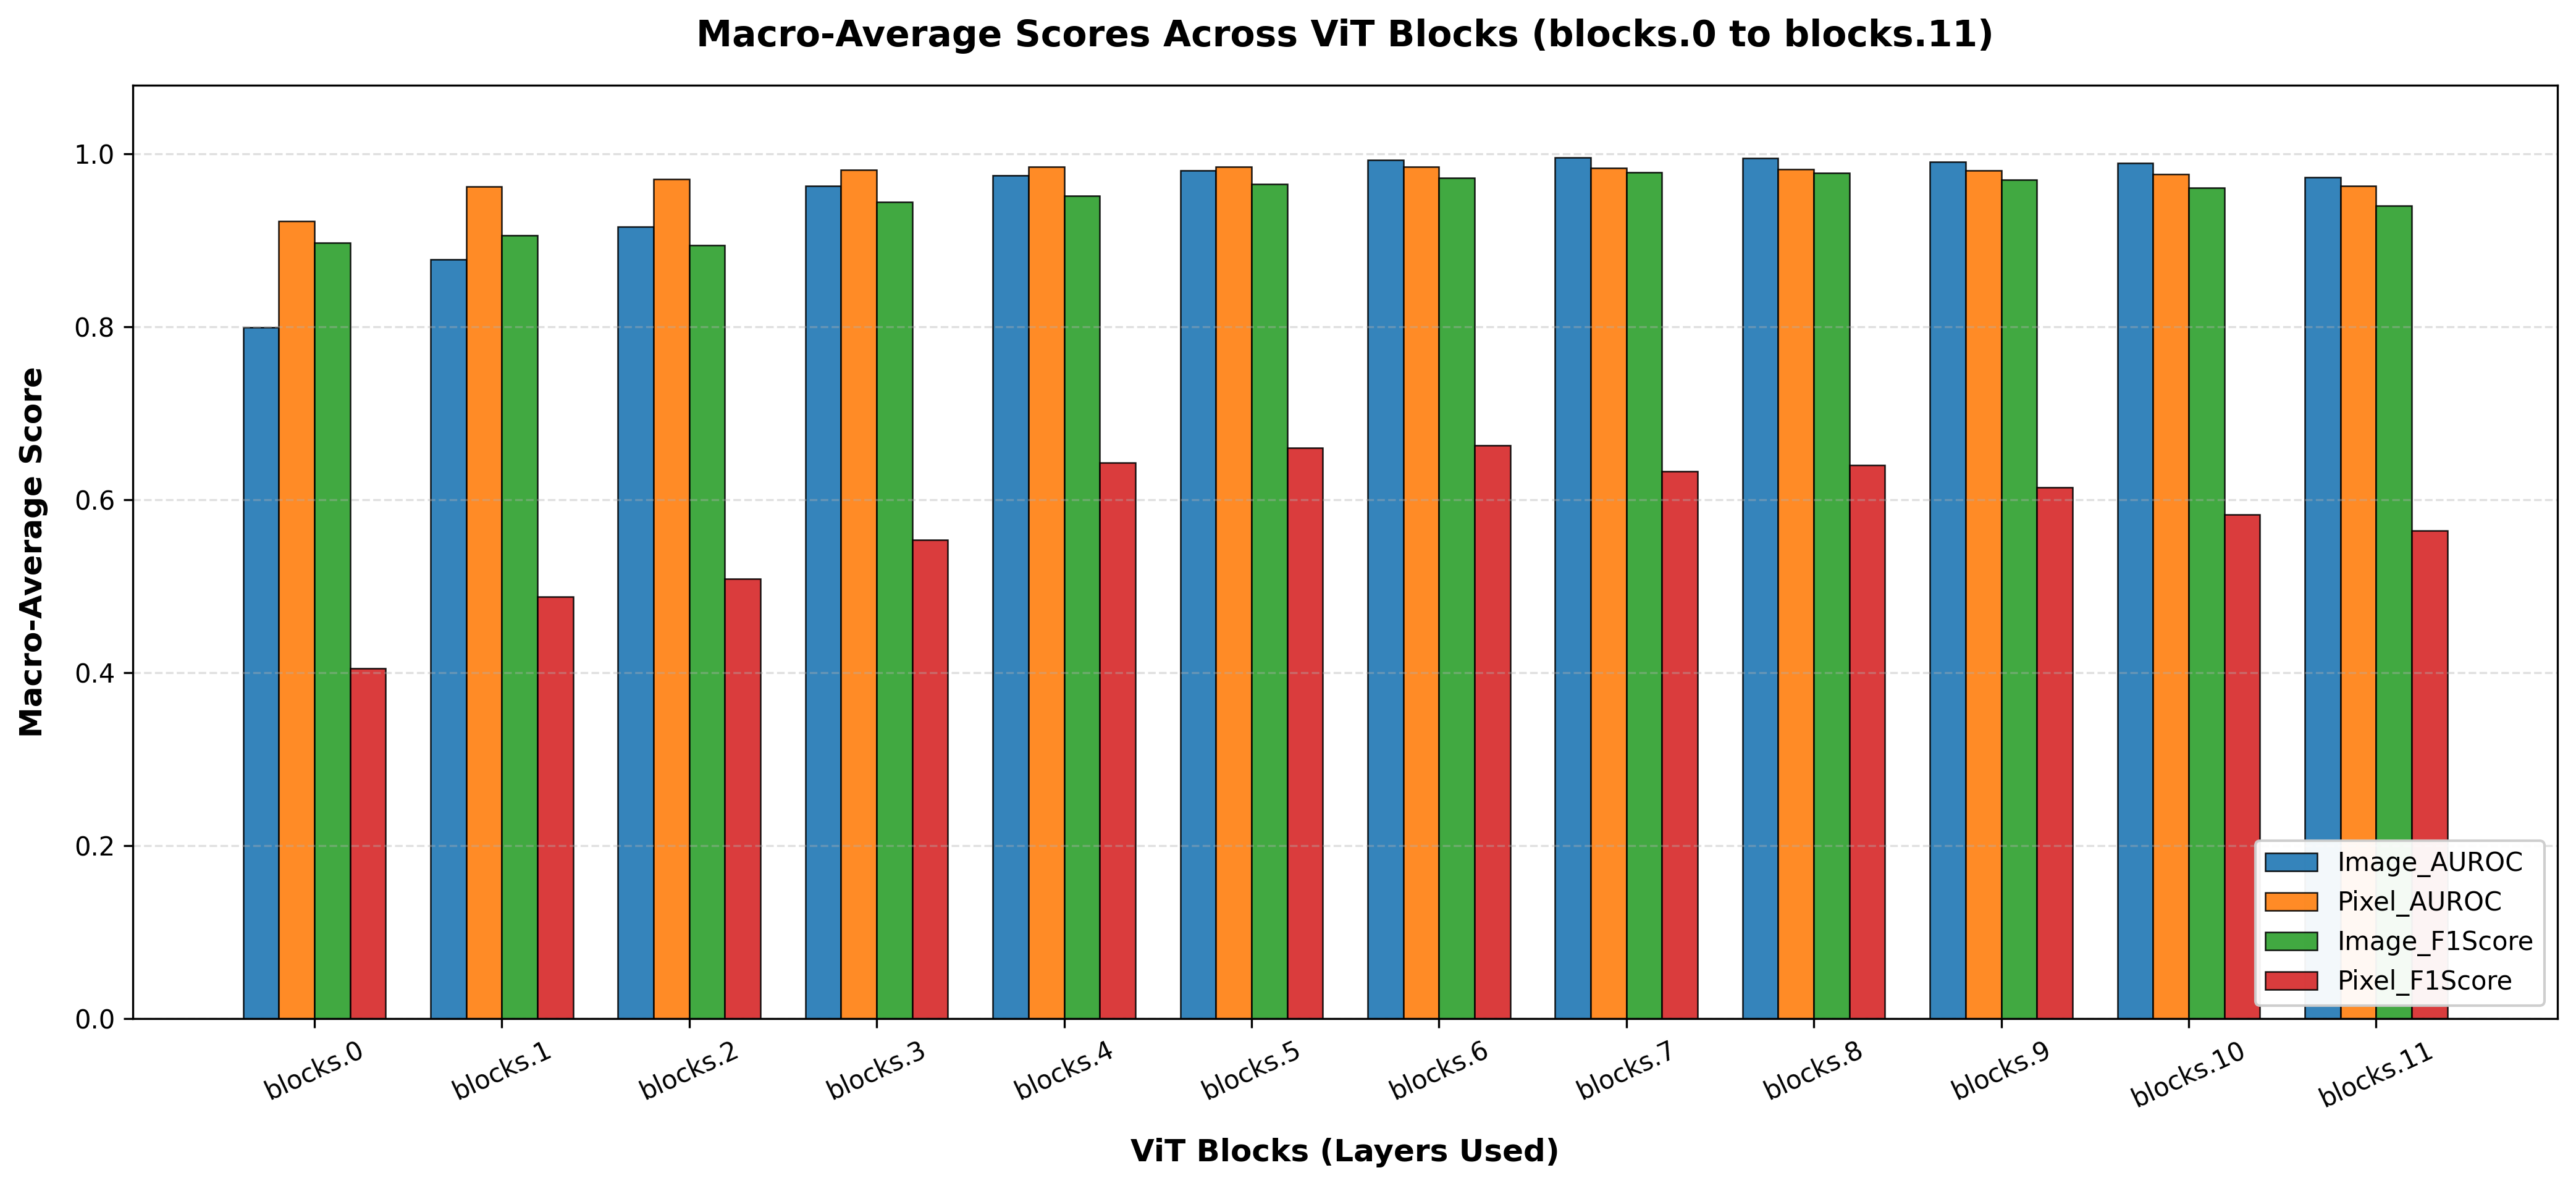

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Configure path inside Drive
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")

# 1. Load data from the Excel file
# Option A: Read the precomputed macro-average summary table (A183:E195)
df_summary = pd.read_excel(
    excel_log_path,
    skiprows=182,  # Header starts at row 183 (0-indexed 182)
    nrows=12,      # 12 blocks (blocks.0 to blocks.11)
    usecols='A:E'
)

# Ensure layers are sorted sequentially from blocks.0 to blocks.11
order = [f'blocks.{i}' for i in range(12)]
df_summary['Layers'] = pd.Categorical(df_summary['Layers'], categories=order, ordered=True)
df_summary = df_summary.sort_values('Layers').reset_index(drop=True)

# 2. Setup plotting parameters
metrics = ['Image_AUROC', 'Pixel_AUROC', 'Image_F1Score', 'Pixel_F1Score']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Blue, Orange, Green, Red

x = np.arange(len(df_summary))
width = 0.19  # Width of each bar

fig, ax = plt.subplots(figsize=(14, 6.5), dpi=300)

# 3. Plot bars for each metric
for i, metric in enumerate(metrics):
    offset = (i - 1.5) * width
    ax.bar(
        x + offset,
        df_summary[metric],
        width,
        label=metric,
        color=colors[i],
        edgecolor='black',
        linewidth=0.6,
        alpha=0.9
    )

# 4. Styling and labels
ax.set_xlabel('ViT Blocks (Layers Used)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Macro-Average Score', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Macro-Average Scores Across ViT Blocks (blocks.0 to blocks.11)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df_summary['Layers'], fontsize=10, rotation=25)
ax.set_ylim(0, 1.08)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='lower right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('blocks_macro_average_metrics.png', dpi=300)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


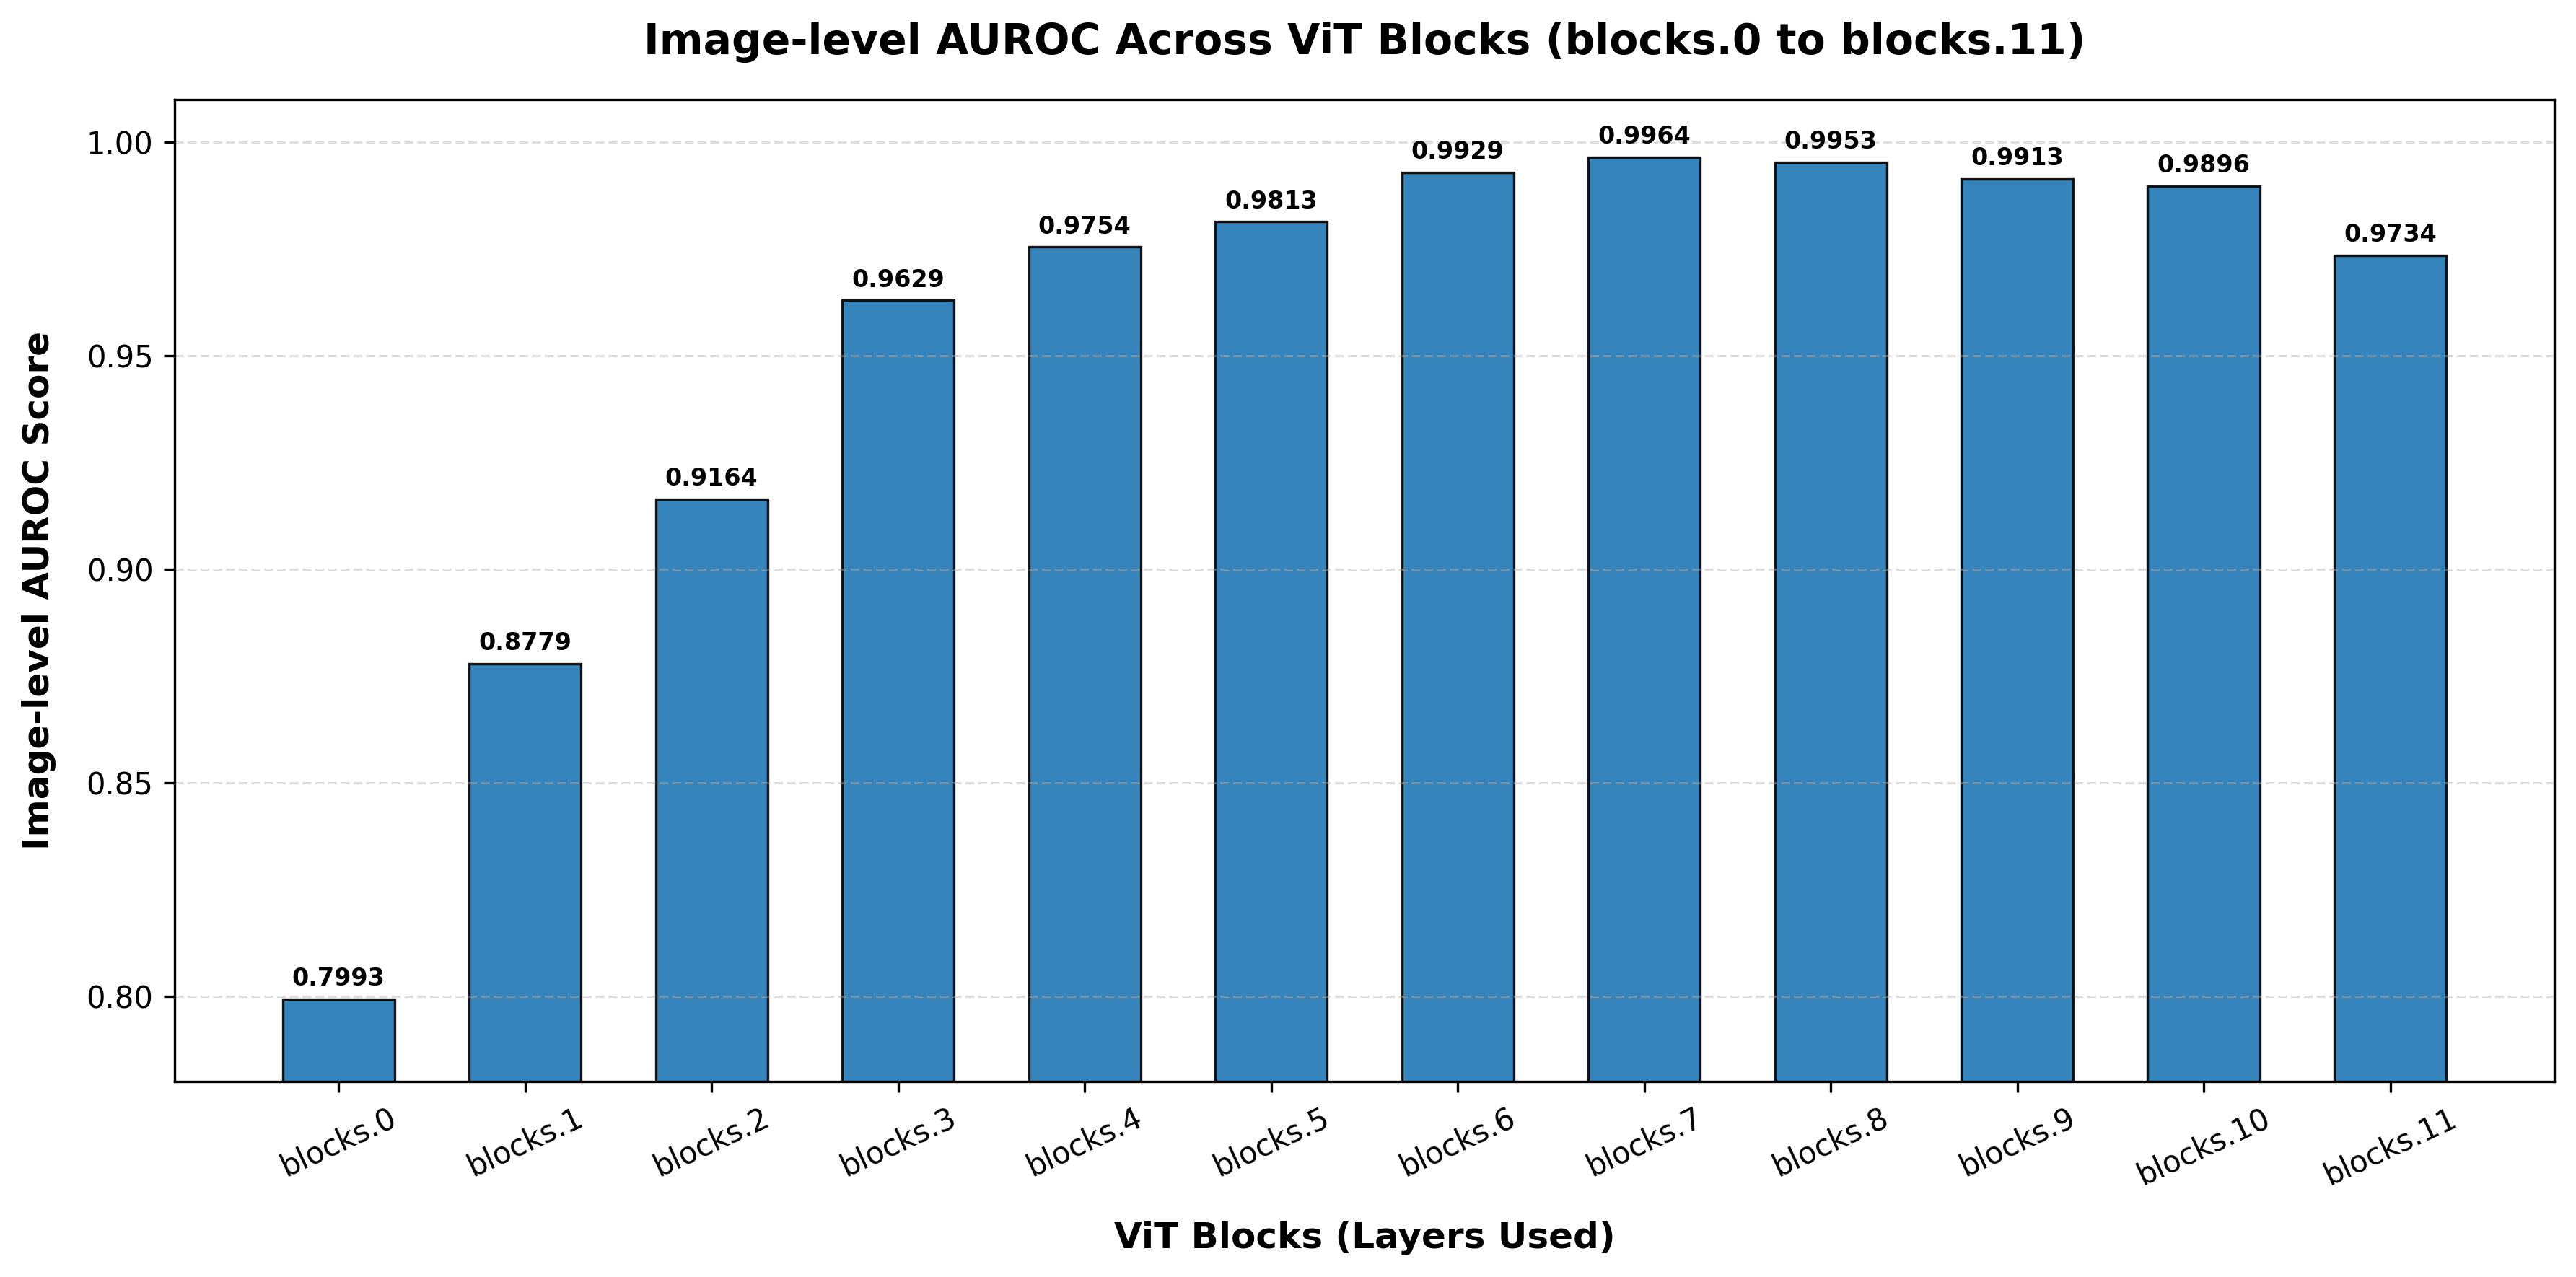

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Configure path inside Drive
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")

# 1. Load data from the Excel file
df_summary = pd.read_excel(
    excel_log_path,
    skiprows=182,  # Header starts at row 183
    nrows=12,      # 12 blocks (blocks.0 to blocks.11)
    usecols='A:E'
)

# Ensure layers are sorted sequentially from blocks.0 to blocks.11
order = [f'blocks.{i}' for i in range(12)]
df_summary['Layers'] = pd.Categorical(df_summary['Layers'], categories=order, ordered=True)
df_summary = df_summary.sort_values('Layers').reset_index(drop=True)

# 2. Setup plotting parameters for single metric
metric = 'Image_AUROC'
color = '#1f77b4'  # Blue color

x = np.arange(len(df_summary))

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

# 3. Plot bars for Image_AUROC
ax.bar(
    x,
    df_summary[metric],
    width=0.6,
    color=color,
    edgecolor='black',
    linewidth=0.8,
    alpha=0.9
)

# Add values on top of the bars
for idx, val in enumerate(df_summary[metric]):
    ax.text(idx, val + 0.002, f"{val:.4f}", ha='center', va='bottom', fontsize=8, fontweight='semibold')

# 4. Styling and labels
ax.set_xlabel('ViT Blocks (Layers Used)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Image-level AUROC Score', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Image-level AUROC Across ViT Blocks (blocks.0 to blocks.11)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df_summary['Layers'], fontsize=10, rotation=25)
ax.set_ylim(0.78, 1.01)  # Adjusted y-axis limits to highlight differences
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('blocks_image_auroc_metric.png', dpi=300)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


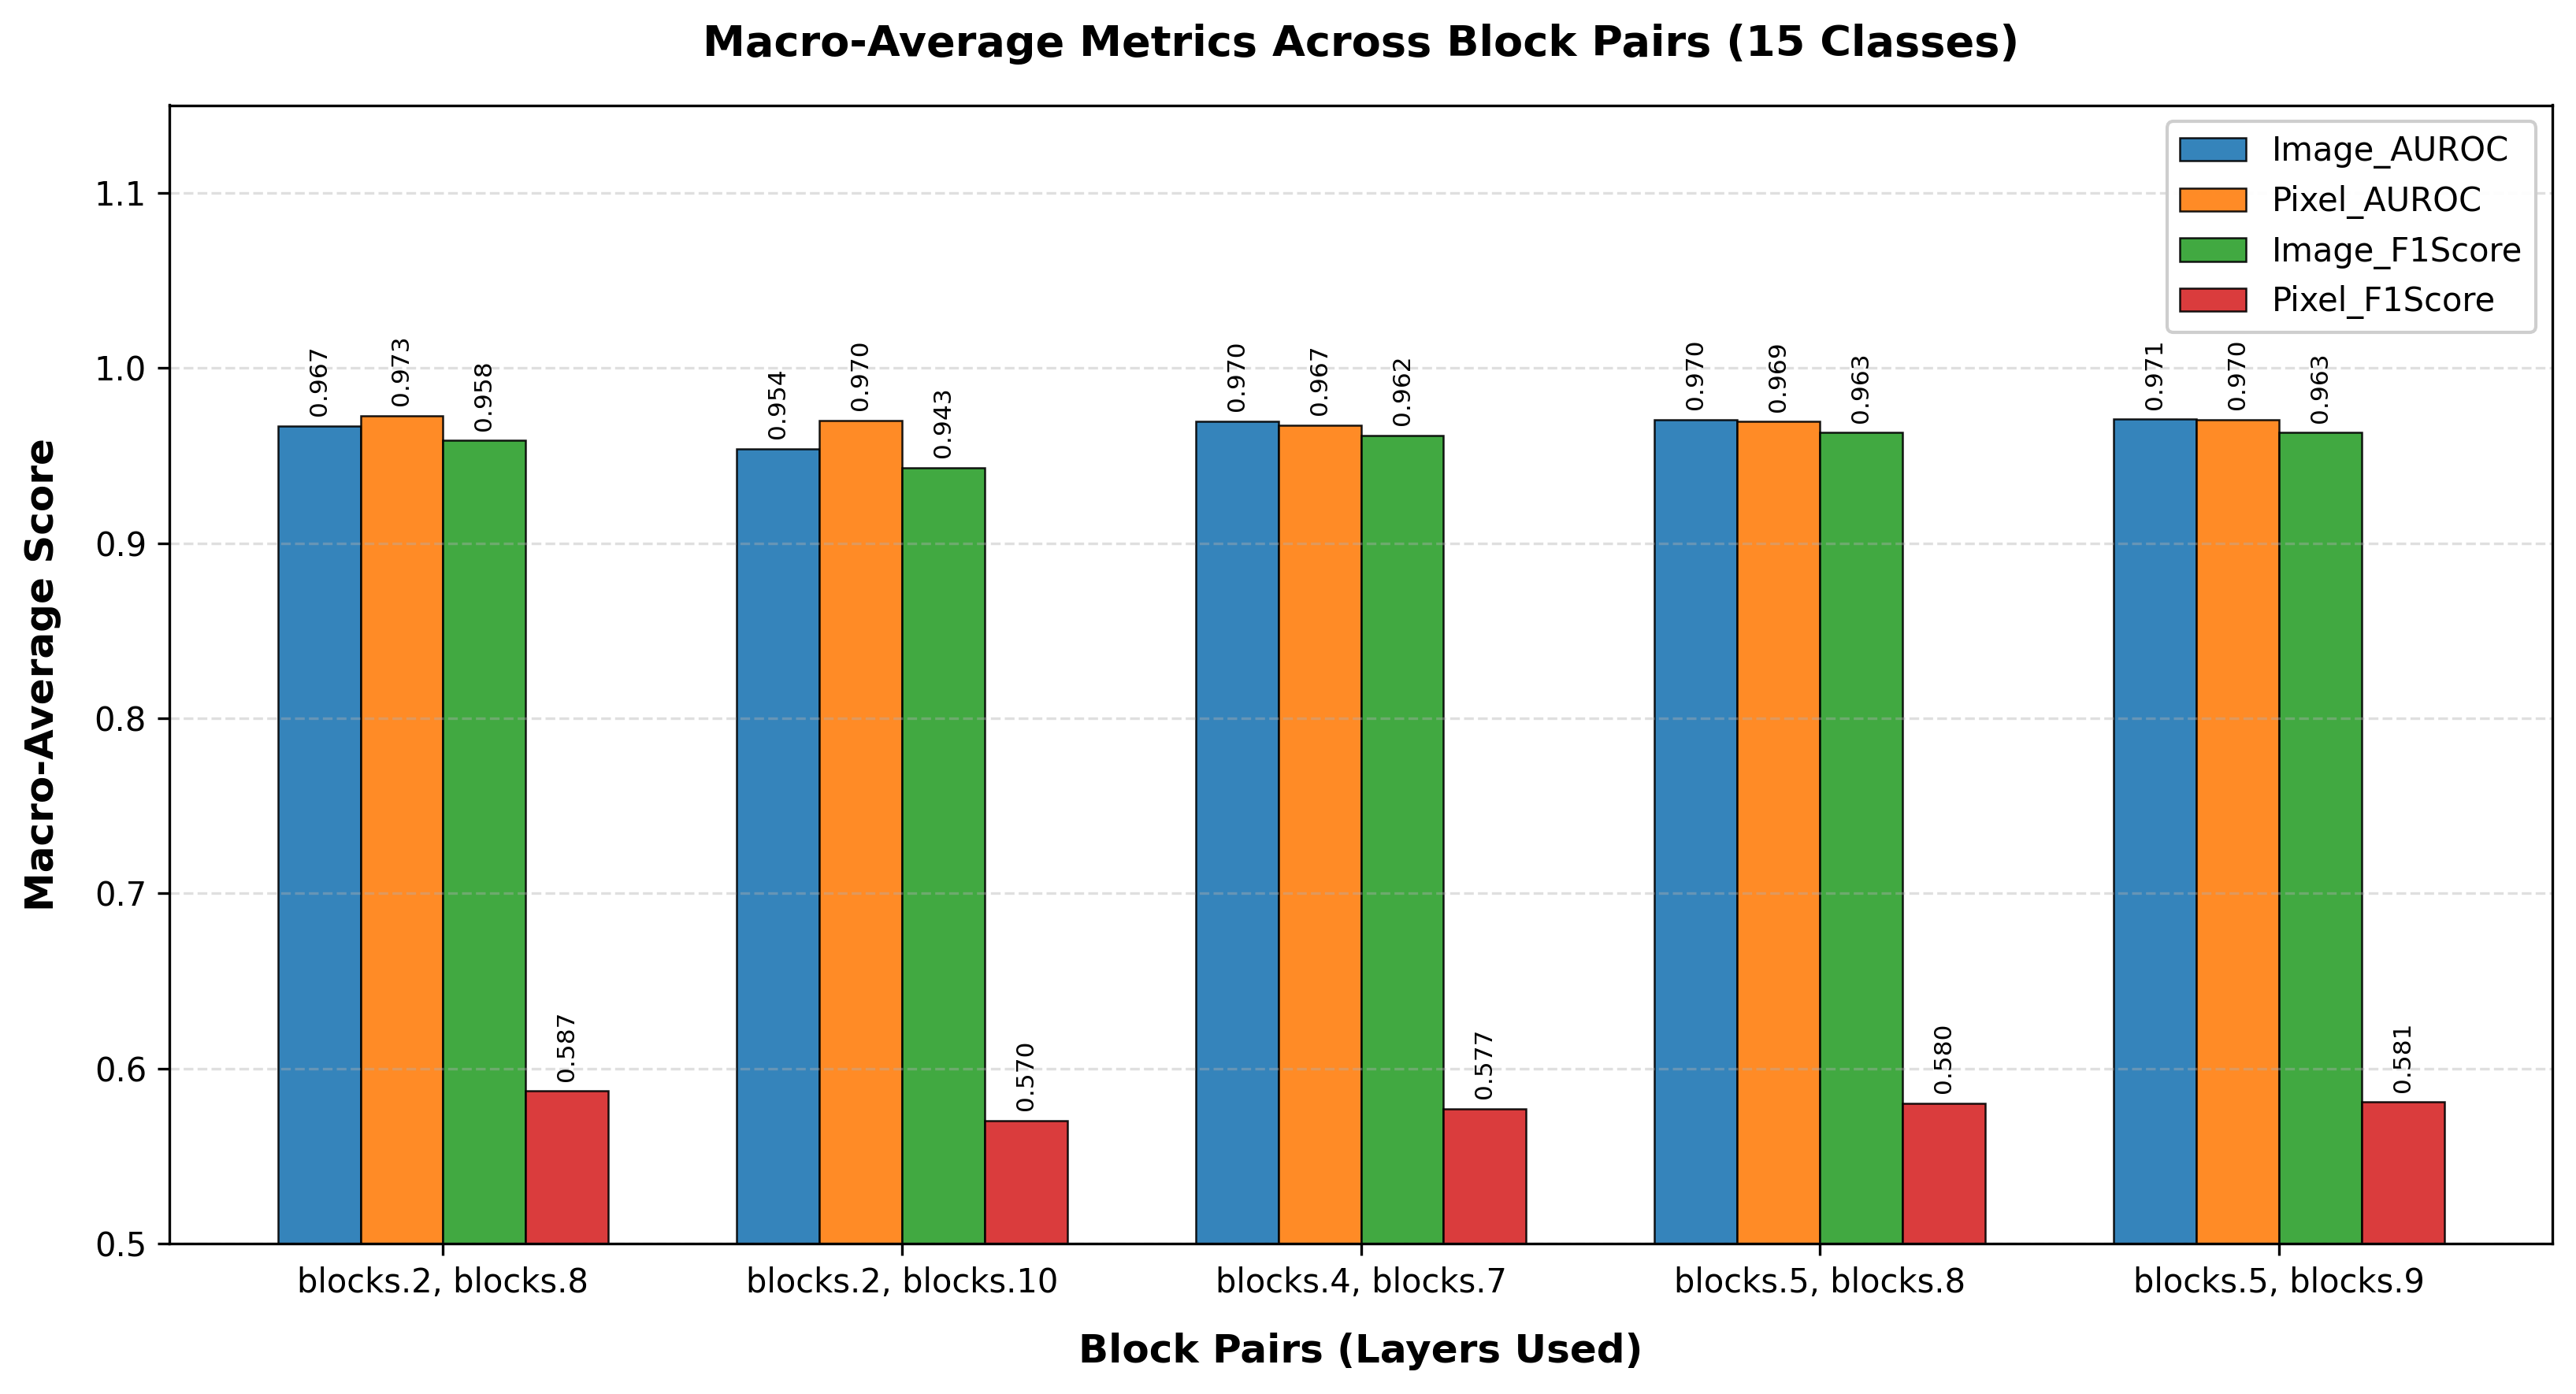

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from pathlib import Path

# 1. Define column names matching the dataset schema
columns = [
    'Timestamp', 'Training_Time_Sec', 'Category', 'Backbone',
    'Layers_Used', 'Coreset_Ratio', 'KNN',
    'Image_AUROC', 'Pixel_AUROC', 'Image_F1Score', 'Pixel_F1Score'
]
drive.mount('/content/drive')
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")

# 2. Load the block-pair experiment rows (A217:K291 -> 75 rows total)
df_pairs = pd.read_excel(
    excel_log_path,
    skiprows=216,   # Row 217 is index 216
    nrows=75,       # 75 rows (15 categories x 5 block pairs)
    header=None,
    names=columns
)

# 3. Compute macro-average scores across all 15 categories for each block pair
metrics = ['Image_AUROC', 'Pixel_AUROC', 'Image_F1Score', 'Pixel_F1Score']
macro_avg = df_pairs.groupby('Layers_Used')[metrics].mean()

# Preserve order of appearance
pairs_order = [
    'blocks.2, blocks.8',
    'blocks.2, blocks.10',
    'blocks.4, blocks.7',
    'blocks.5, blocks.8',
    'blocks.5, blocks.9'
]
macro_avg = macro_avg.reindex(pairs_order).reset_index()

# 4. Plot setup
x = np.arange(len(macro_avg))
width = 0.18
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, ax = plt.subplots(figsize=(11, 6), dpi=300)

for i, metric in enumerate(metrics):
    offset = (i - 1.5) * width
    rects = ax.bar(
        x + offset,
        macro_avg[metric],
        width,
        label=metric,
        color=colors[i],
        edgecolor='black',
        linewidth=0.6,
        alpha=0.9
    )

    # Optional: Display numerical value above each bar
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f'{height:.3f}',
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 3),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=7.5,
            rotation=90
        )

# 5. Styling and labels
ax.set_xlabel('Block Pairs (Layers Used)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Macro-Average Score', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Macro-Average Metrics Across Block Pairs (15 Classes)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(macro_avg['Layers_Used'], fontsize=10)
ax.set_ylim(0.5, 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='upper right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('block_pairs_macro_average.png', dpi=300)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


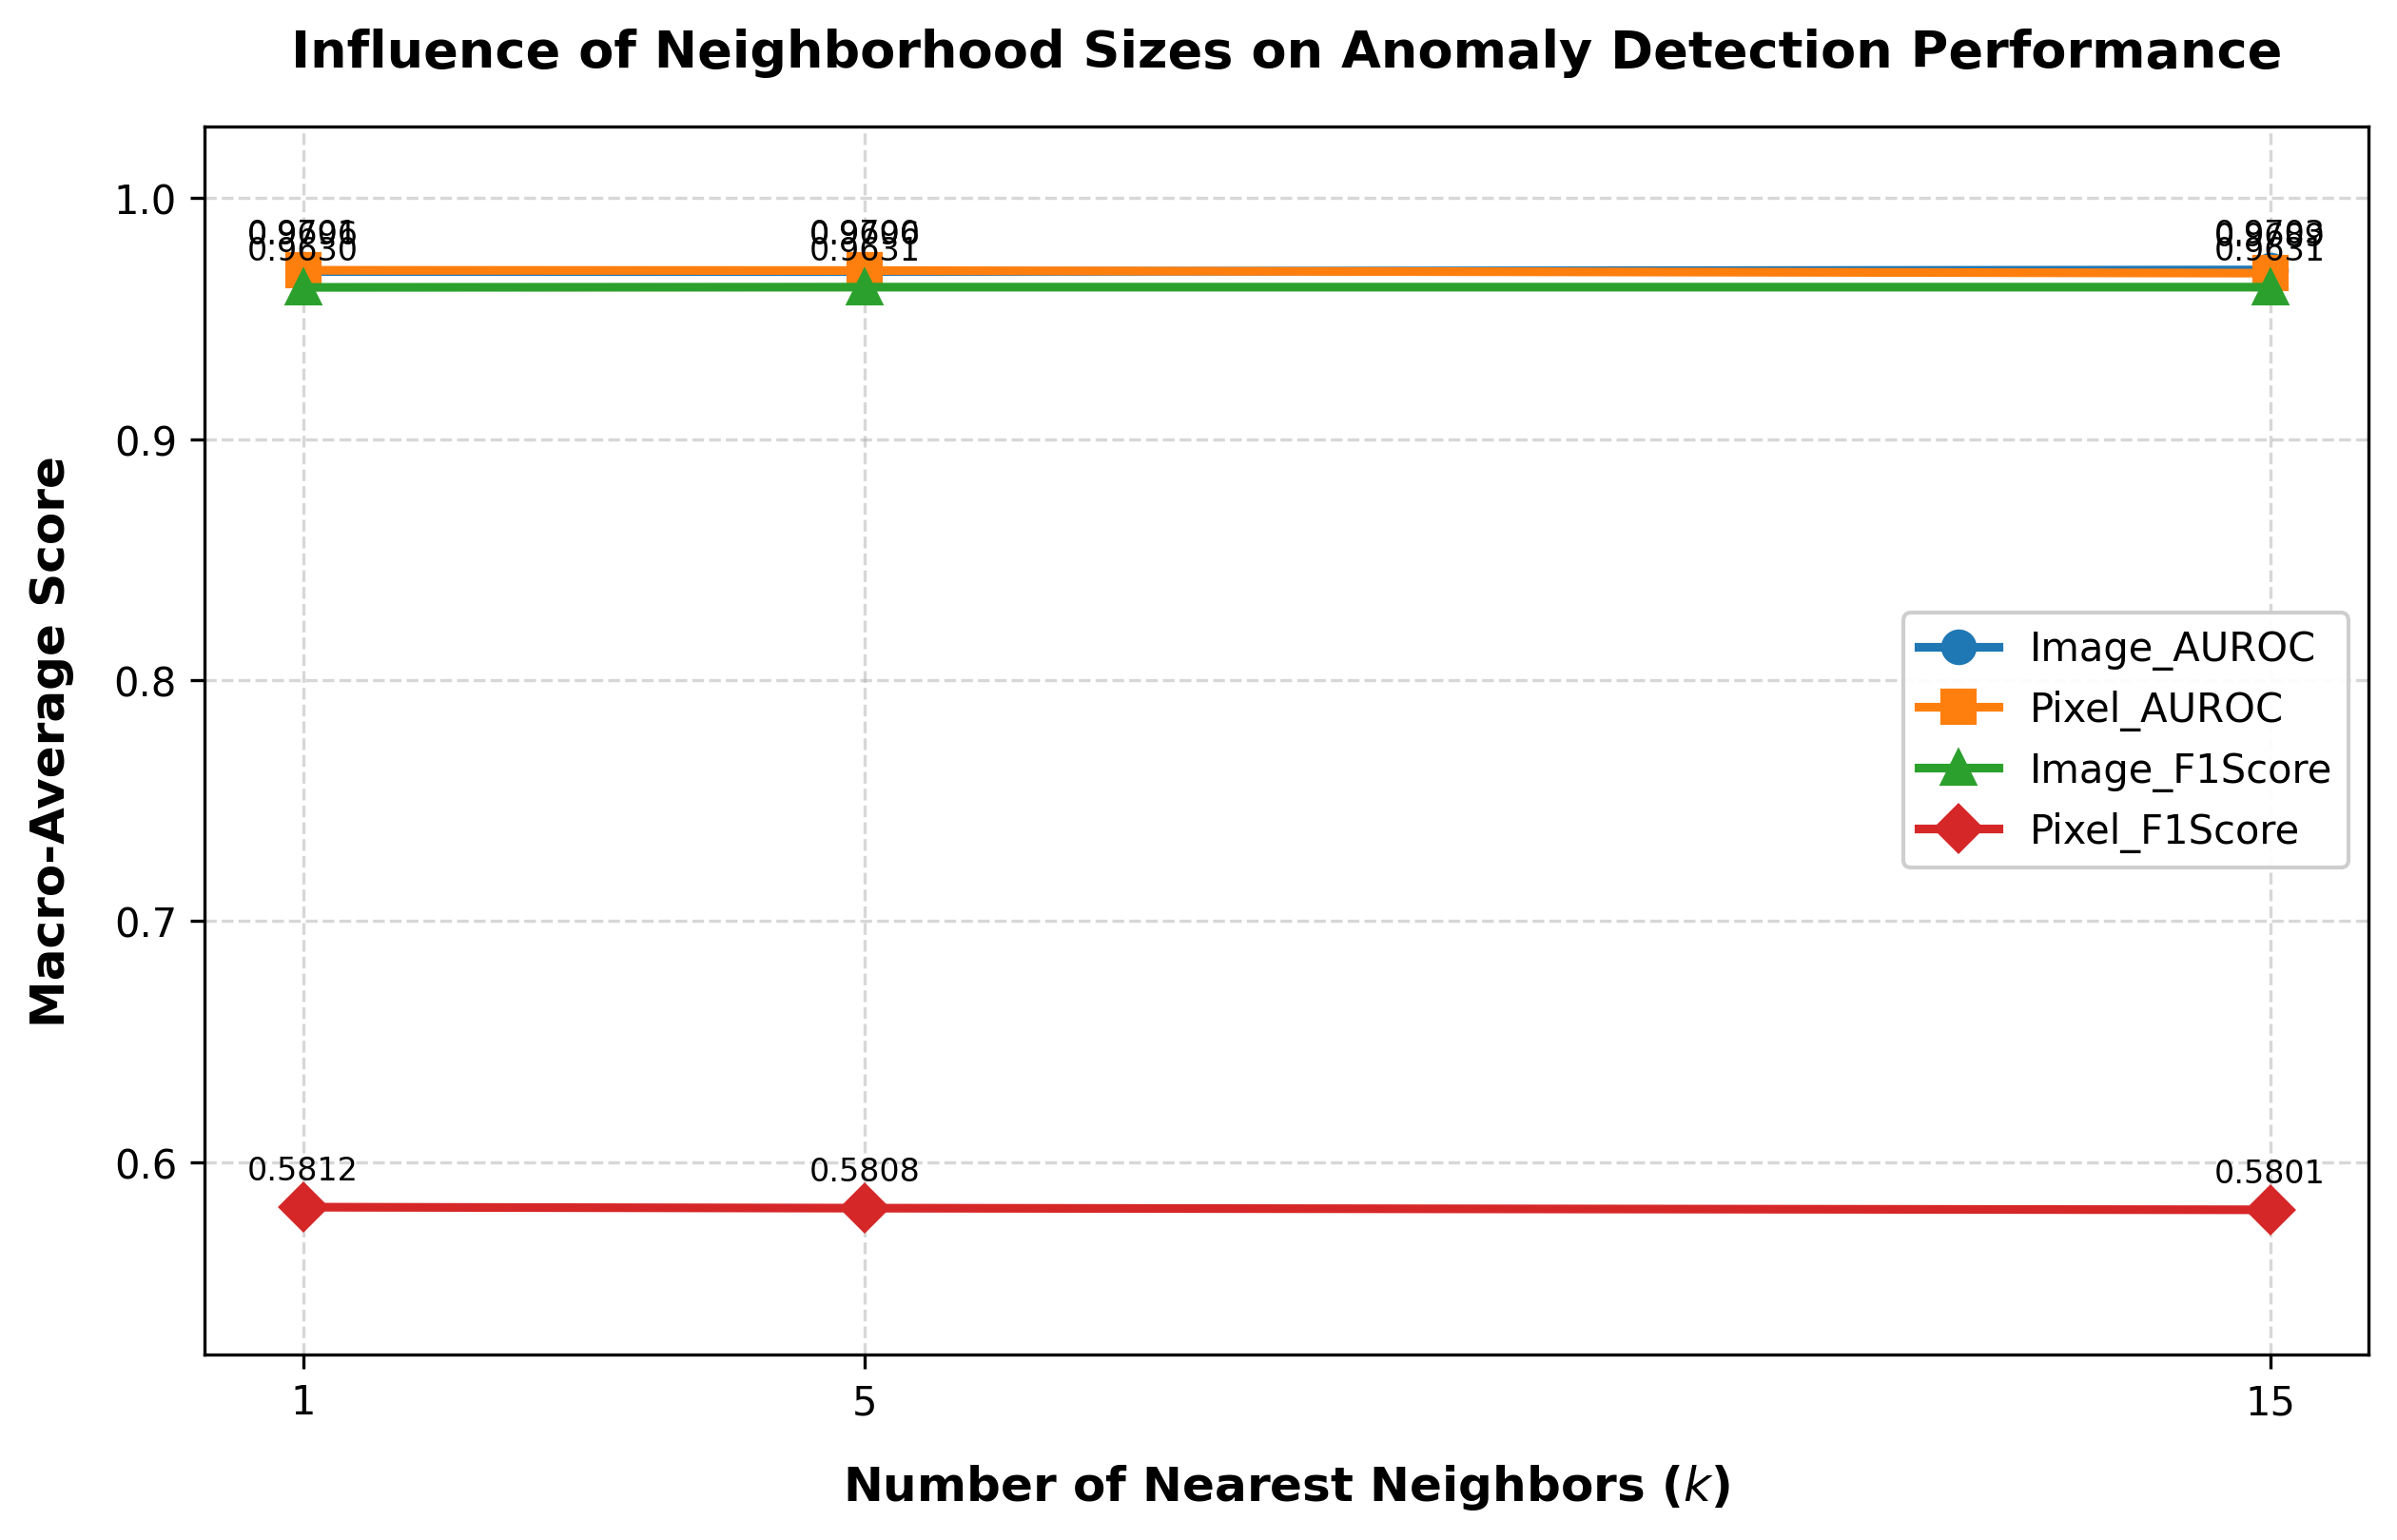

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from pathlib import Path

# 1. Define column names matching the dataset schema
columns = [
    'Timestamp', 'Training_Time_Sec', 'Category', 'Backbone',
    'Layers_Used', 'Coreset_Ratio', 'KNN',
    'Image_AUROC', 'Pixel_AUROC', 'Image_F1Score', 'Pixel_F1Score'
]
drive.mount('/content/drive')
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v2.xlsx")

# 2. Read rows 294 to 338 (45 rows: 15 classes x 3 KNN settings)
df_knn = pd.read_excel(
    excel_log_path,
    skiprows=293,  # Row 294 is 0-indexed 293
    nrows=45,
    header=None,
    names=columns
)

# 3. Compute macro-average across all 15 classes for each neighbor size
metrics = ['Image_AUROC', 'Pixel_AUROC', 'Image_F1Score', 'Pixel_F1Score']
knn_macro = df_knn.groupby('KNN')[metrics].mean()

knn_values = [1, 5, 15]
markers = ['o', 's', '^', 'D']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# -------------------------------------------------------------
# Style 1: Line Plot (Matches Figure 4 of the PatchCore Paper)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)

for i, metric in enumerate(metrics):
    y_vals = knn_macro.loc[knn_values, metric].values
    ax.plot(
        knn_values,
        y_vals,
        marker=markers[i],
        linewidth=2.2,
        markersize=8,
        label=metric,
        color=colors[i]
    )
    # Add numerical labels next to each point
    for x_val, y_val in zip(knn_values, y_vals):
        ax.annotate(
            f"{y_val:.4f}",
            (x_val, y_val),
            textcoords="offset points",
            xytext=(0, 7),
            ha='center',
            fontsize=8
        )

ax.set_xlabel('Number of Nearest Neighbors ($k$)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Macro-Average Score', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Influence of Neighborhood Sizes on Anomaly Detection Performance', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(knn_values)
ax.set_ylim(0.52, 1.03)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='center right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('figure4_influence_of_neighborhood_sizes.png', dpi=300)
plt.show()

# Testing different backbones and layers in PatchCore V3

In [ ]:
import timm
print(timm.create_model("vit_large_patch16_dinov3", features_only=True).feature_info.module_name())

['blocks.21', 'blocks.22', 'blocks.23']


In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, PRO

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v3_1.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "wide_resnet50_2"
CORESET_RATIO = [0.01, 0.10, 0.25, 1.0]
KNN_NEIGHBORS = 1
layer_experiments = ["layer2", "layer3"]

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
    # Image-level
    AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
    F1Score(prefix="image_", fields=["pred_label", "gt_label"]),

    # Pixel-level (AUROC and PRO require floating-point anomaly_map)
    AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
    F1Score(prefix="pixel_", fields=["pred_mask", "gt_mask"]),
    PRO(fields=["anomaly_map", "gt_mask"]),
]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layer_experiments,
        coreset_sampling_ratio=coreset_ratio,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}
    # print(f"Available keys in test_results: {list(test_results.keys())}")

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
    pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
    image_f1 = test_results.get("image_F1Score", test_results.get("image_f1score", 0.0))
    pixel_f1 = test_results.get("pixel_F1Score", test_results.get("pixel_f1score", 0.0))
    pro_score = test_results.get("PRO", test_results.get("pro", 0.0))

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layer_experiments),
        "Coreset_Ratio": coreset_ratio,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "Image_F1Score": round(float(image_f1), 4),
        "Pixel_F1Score": round(float(pixel_f1), 4),
        "PRO": round(float(pro_score), 4),
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

    # Display current logged history
    print("\n========== EXPERIMENT LOG HISTORY ==========")
    print(updated_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

...

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 252927/252927 [17:05<00:00, 246.55it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.


Training completed in: 1047.36s (17.46 min)
Running test evaluation...


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│            PRO            │    0.6465762257575989     │
│        image_AUROC        │    0.9850876927375793     │
│       image_F1Score       │    0.9572649598121643     │
│        pixel_AUROC        │     0.931527316570282     │
│       pixel_F1Score       │    0.4712315797805786     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v3_1.xlsx

========== EXPERIMENT LOG HISTORY ==========
          Timestamp  Training_Time_Sec          Category                 Backbone                                         Layers_Used  Coreset_Ratio  KNN  Image_AUROC  Pixel_AUROC  Image_F1Score  Pixel_F1Score    PRO
2026-09-16 15:35:16              14.27     bottle object vit_large_patch16_dinov3 blocks.0, blocks.5, blocks.11, blocks.17, blocks.23           0.01    1       0.9992       0.9883         0.9841         0.7644 0.7261
2026-09-16 15:46:30              20.57     bottle object vit_large_patch16_dinov3 blocks.0, blocks.5, blocks.11, blocks.17, blocks.23           0.10    1       1.0000       0.9889         0.9920         0.7666 0.7107
2026-09-16 15:49:30             159.27     bottle object vit_large_patch16_dinov3 blocks.0, blocks.5, blocks.11, blocks.17, blocks.23           0.25    1       1.0000       0.9890        

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


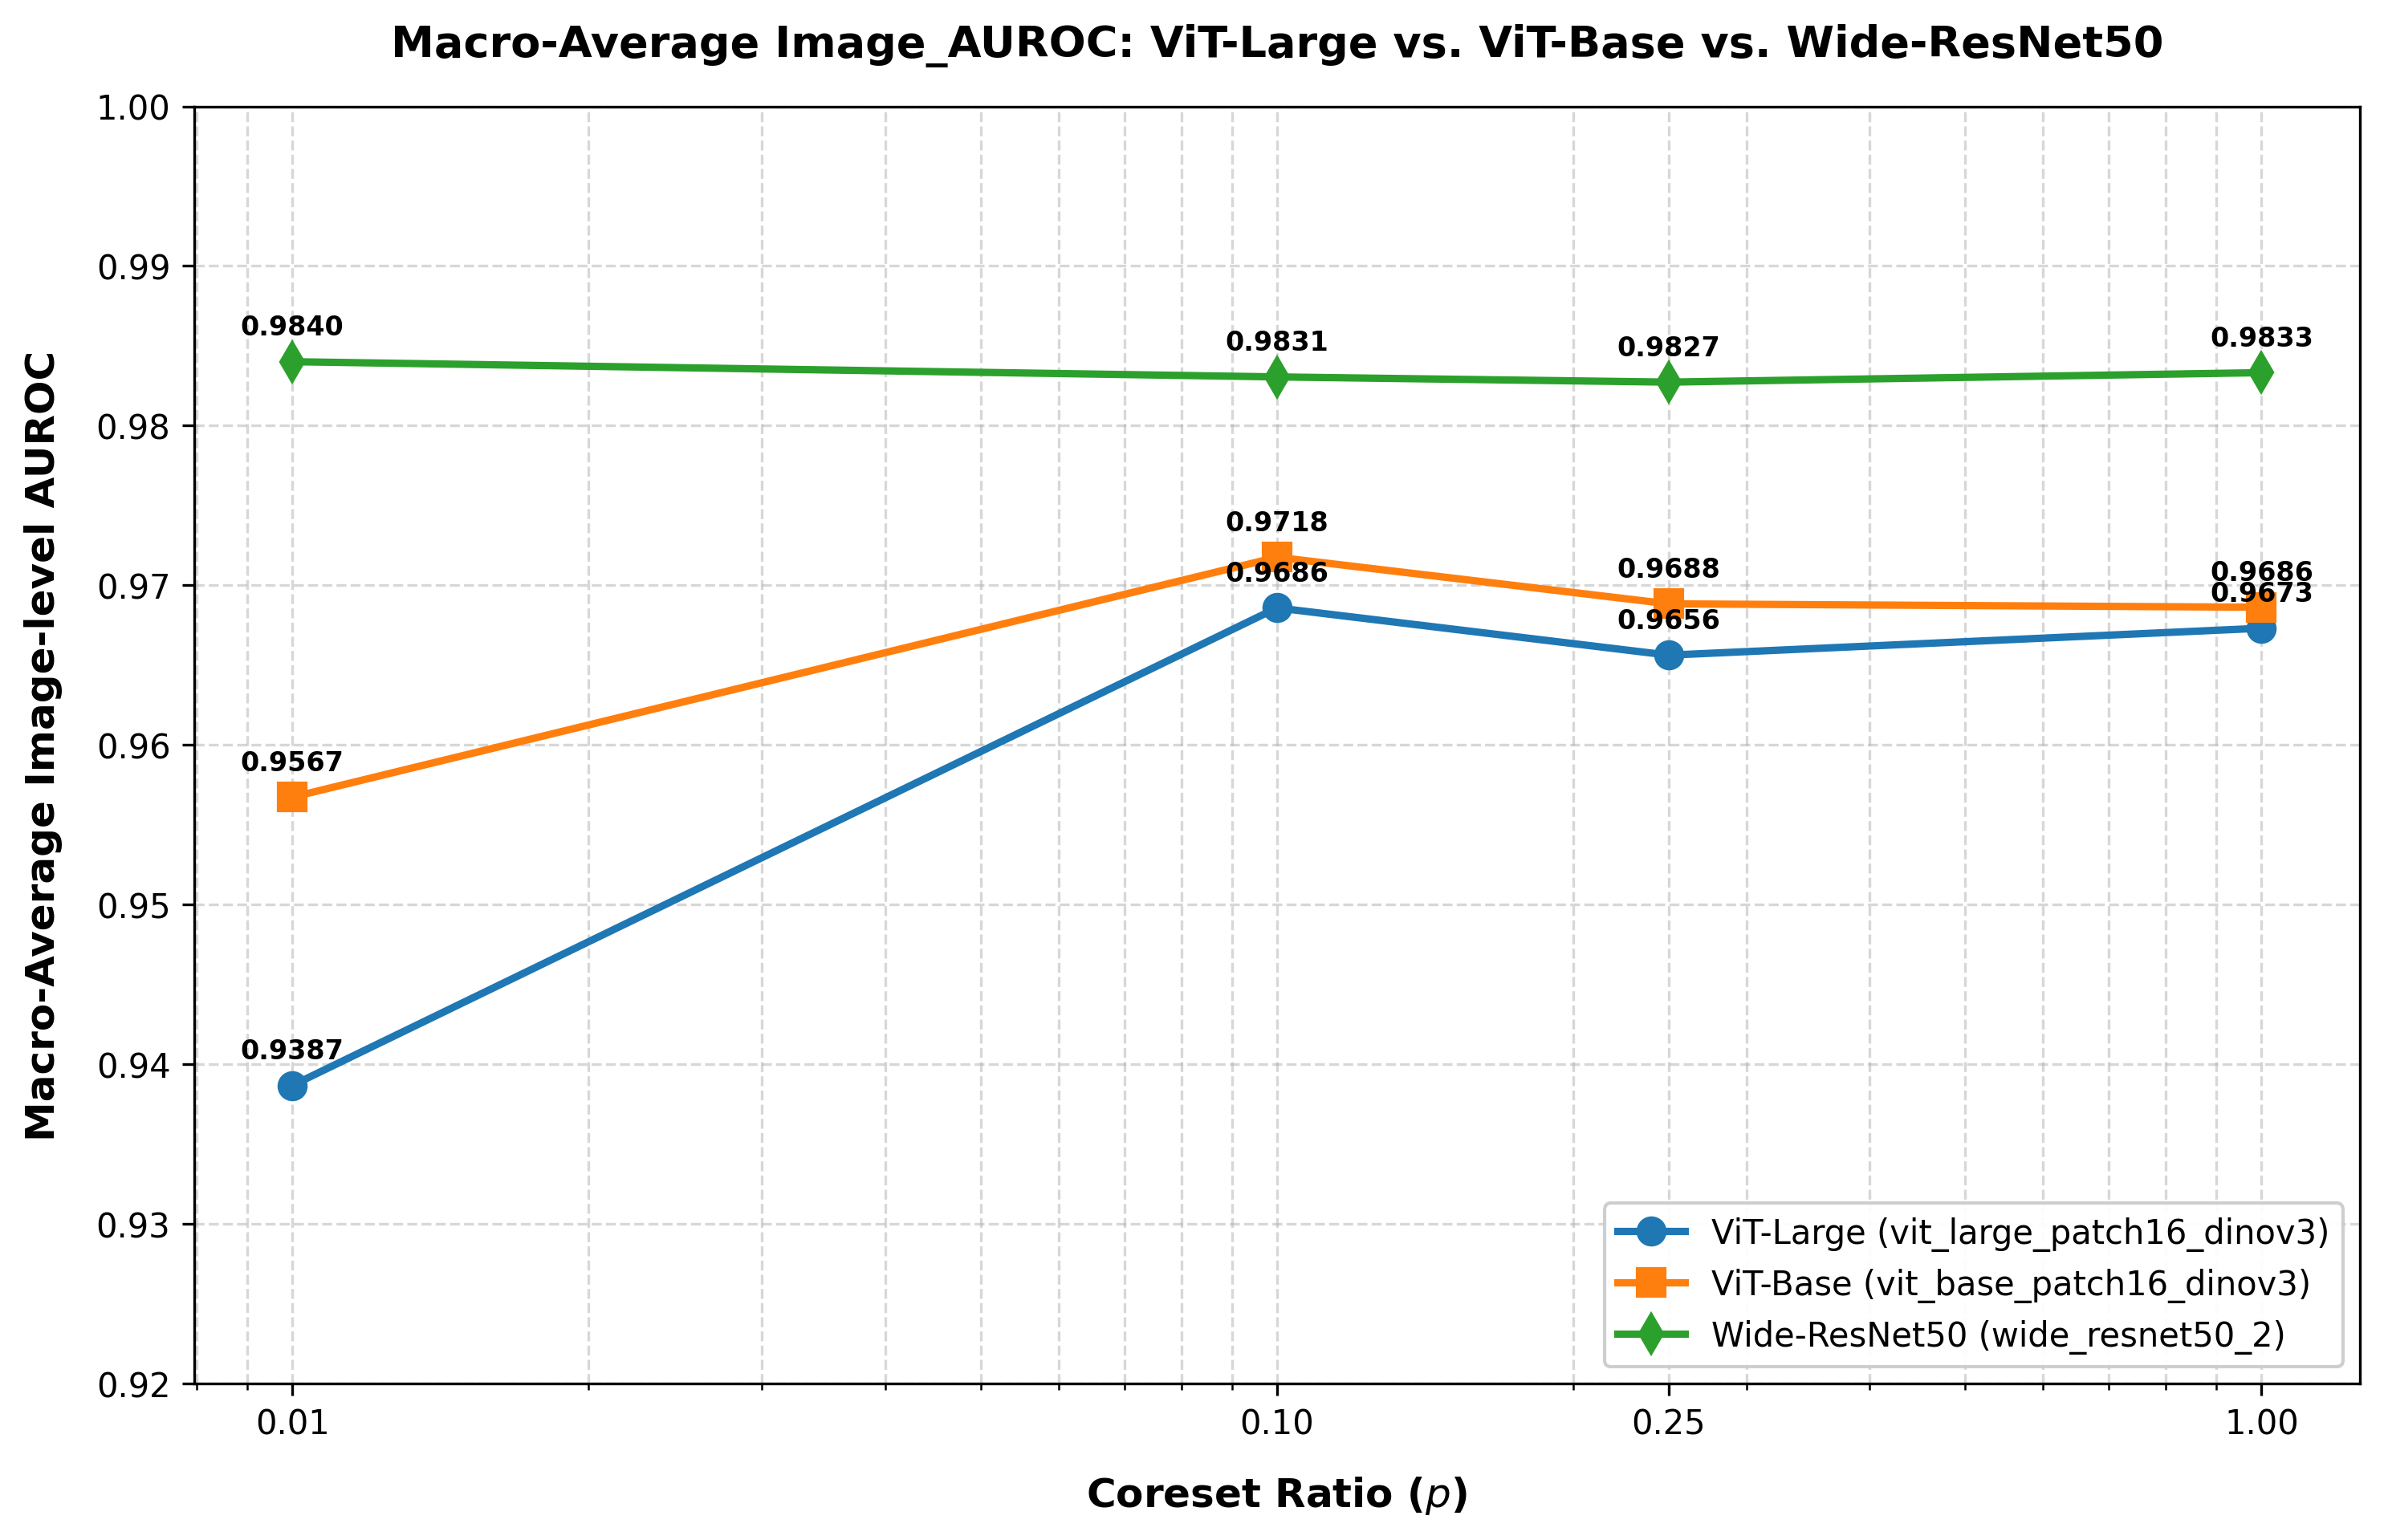

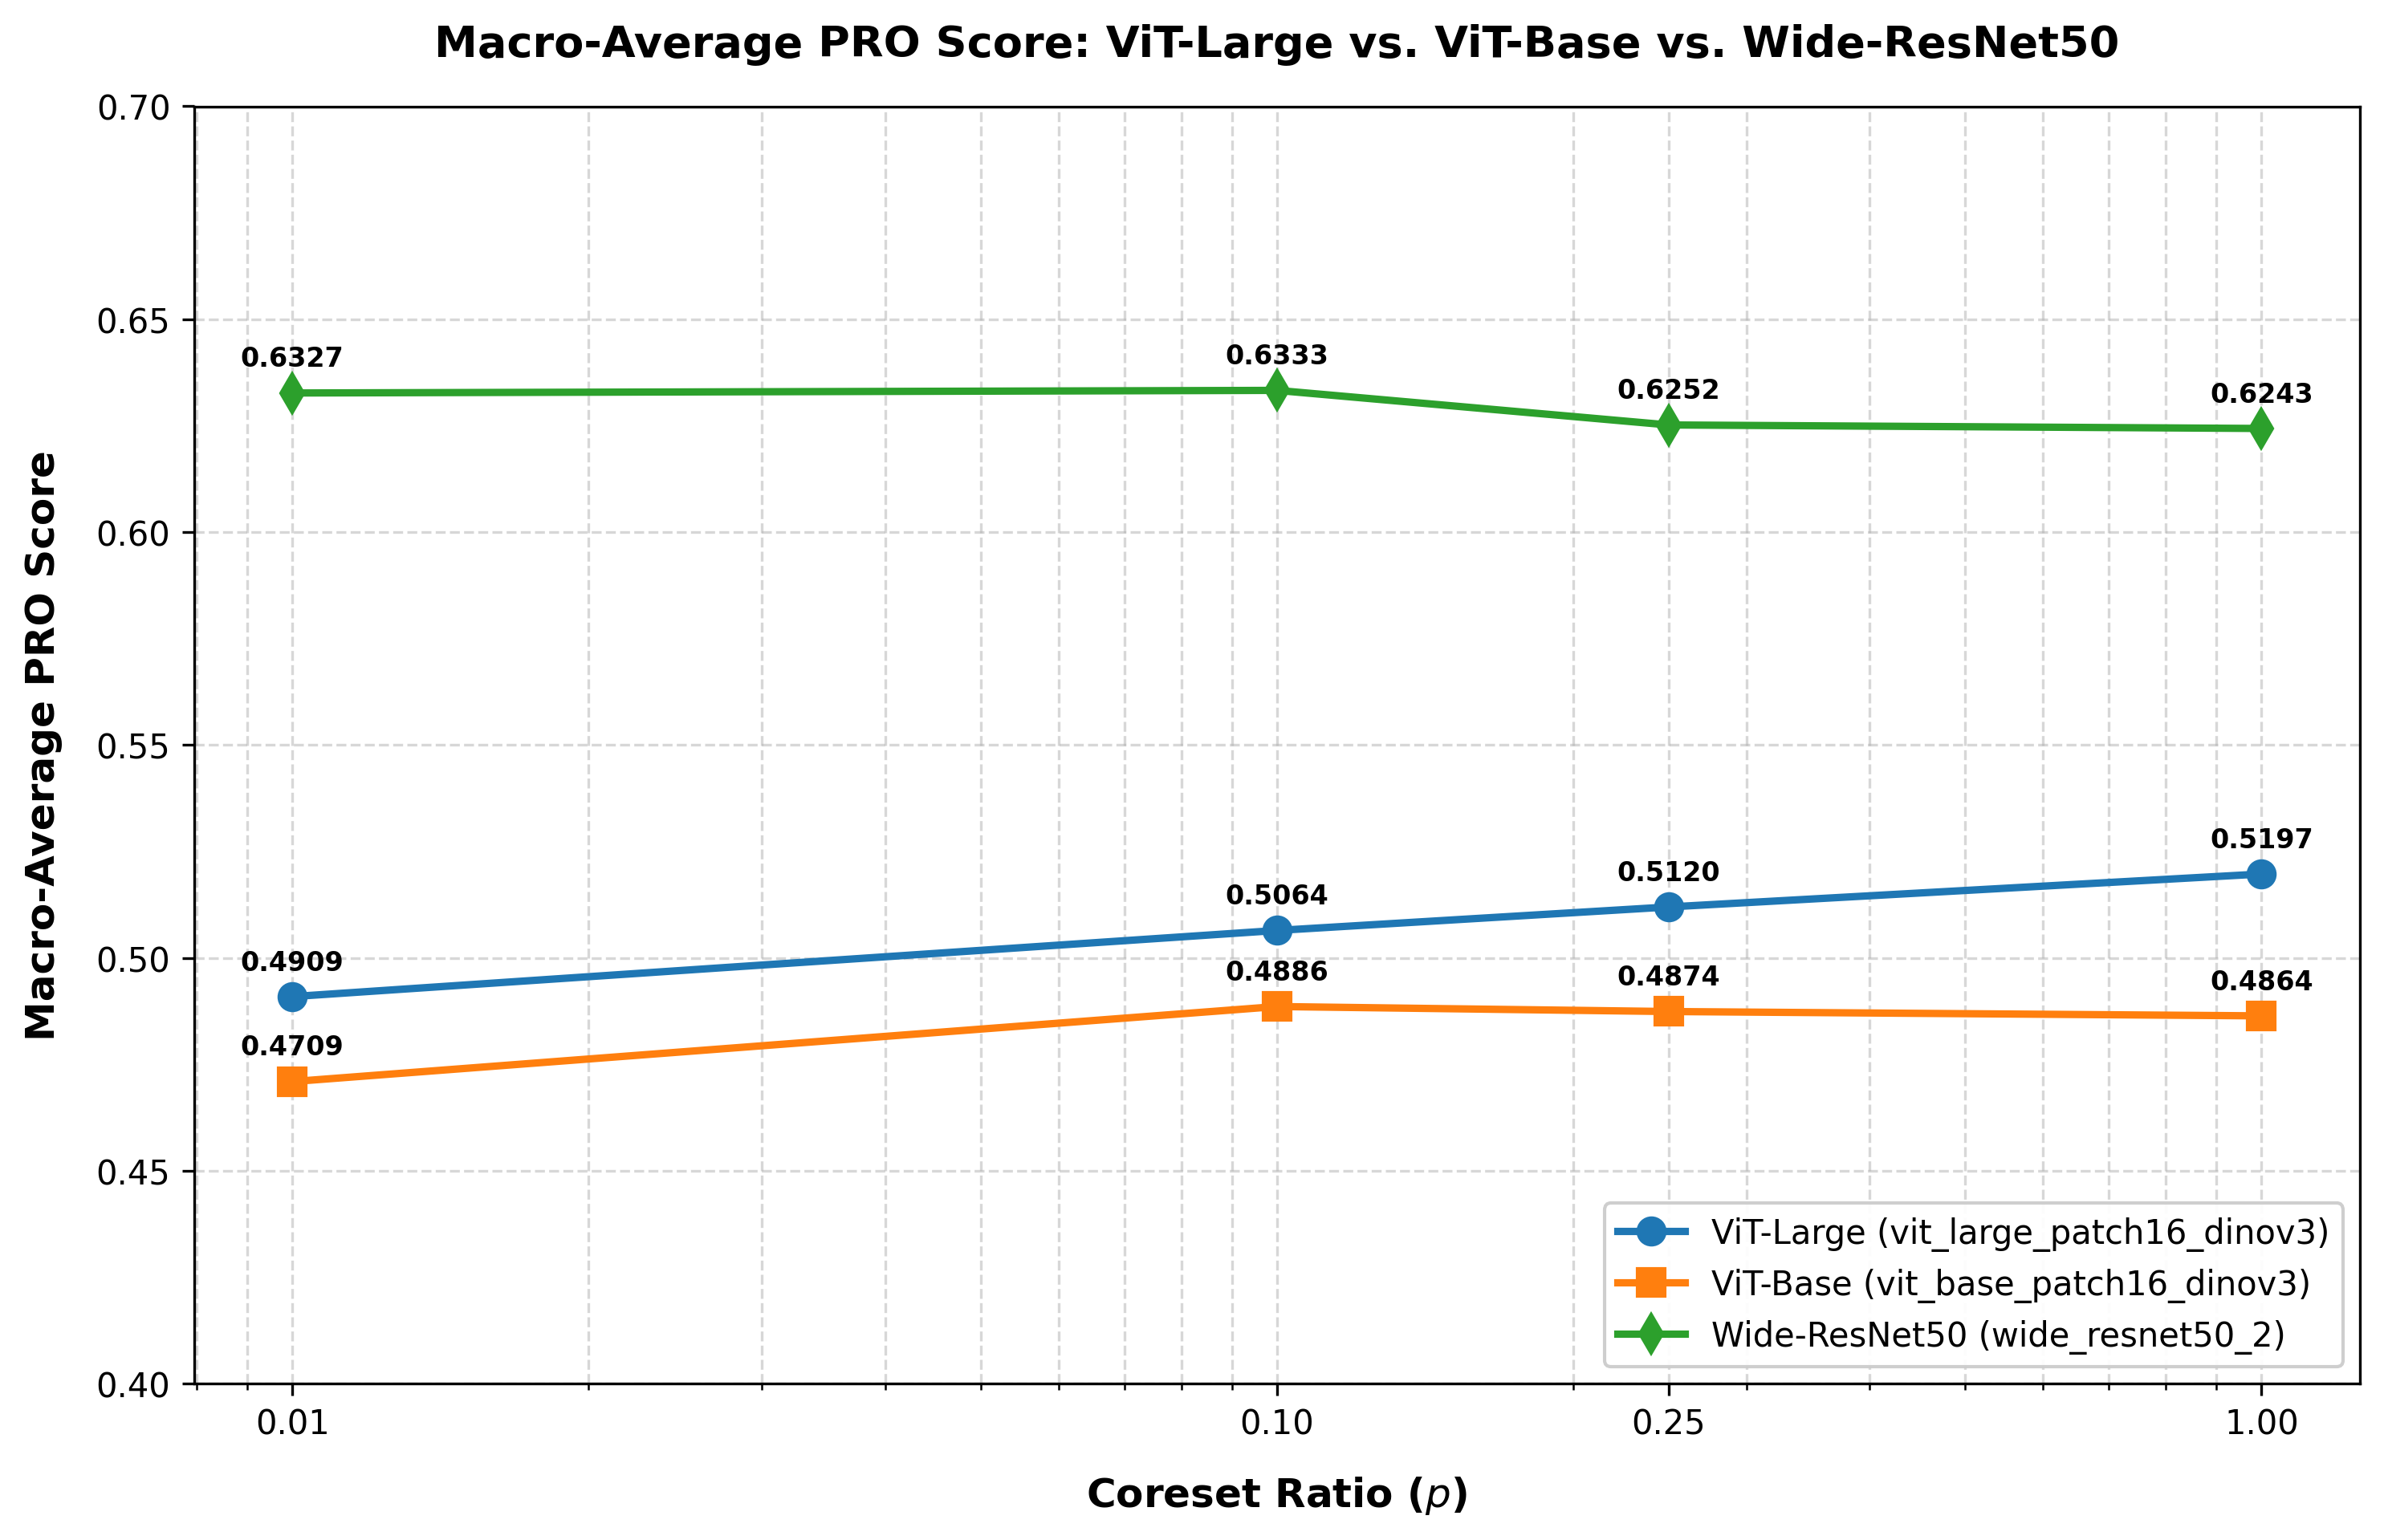

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive and load the cleaned dataset
drive.mount('/content/drive')
excel_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v3_1.xlsx")

if not excel_path.exists():
    raise FileNotFoundError(f"File not found at: {excel_path}")

df = pd.read_excel(excel_path)

# 2. Filter for the three target backbones
target_backbones = ['vit_large_patch16_dinov3', 'vit_base_patch16_dinov3', 'wide_resnet50_2']
df_filtered = df[df['Backbone'].isin(target_backbones)].copy()

# 3. Group by Backbone and Coreset_Ratio to compute the macro-averages (mean of 15 classes)
metrics = ['Image_AUROC', 'PRO']
macro_avg = df_filtered.groupby(['Backbone', 'Coreset_Ratio'])[metrics].mean().reset_index()

# Ensure ratios are treated as numbers and sorted sequentially
ratios = [0.01, 0.10, 0.25, 1.00]
macro_avg = macro_avg[macro_avg['Coreset_Ratio'].isin(ratios)].sort_values(['Backbone', 'Coreset_Ratio'])

# Split data by backbone for plotting
large_data = macro_avg[macro_avg['Backbone'] == 'vit_large_patch16_dinov3']
base_data = macro_avg[macro_avg['Backbone'] == 'vit_base_patch16_dinov3']
wrn_data = macro_avg[macro_avg['Backbone'] == 'wide_resnet50_2']

markers = {
    'vit_large_patch16_dinov3': 'o',
    'vit_base_patch16_dinov3': 's',
    'wide_resnet50_2': 'd'
}
colors = {
    'vit_large_patch16_dinov3': '#1f77b4',
    'vit_base_patch16_dinov3': '#ff7f0e',
    'wide_resnet50_2': '#2ca02c'
}
labels = {
    'vit_large_patch16_dinov3': 'ViT-Large (vit_large_patch16_dinov3)',
    'vit_base_patch16_dinov3': 'ViT-Base (vit_base_patch16_dinov3)',
    'wide_resnet50_2': 'Wide-ResNet50 (wide_resnet50_2)'
}

# -----------------------------------------------------------------
# Figure 1: Image-level AUROC vs. Coreset Ratios
# -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=300)

for backbone, data_group in [('vit_large_patch16_dinov3', large_data), ('vit_base_patch16_dinov3', base_data), ('wide_resnet50_2', wrn_data)]:
    if not data_group.empty:
        ax.plot(
            data_group['Coreset_Ratio'],
            data_group['Image_AUROC'],
            marker=markers[backbone],
            color=colors[backbone],
            linewidth=2.2,
            markersize=8,
            label=labels[backbone]
        )

        # Annotate numerical values
        for x_v, y_v in zip(data_group['Coreset_Ratio'], data_group['Image_AUROC']):
            ax.annotate(
                f"{y_v:.4f}",
                (x_v, y_v),
                textcoords="offset points",
                xytext=(0, 8),
                ha='center',
                fontsize=8,
                fontweight='semibold'
            )

ax.set_xlabel('Coreset Ratio ($p$)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Macro-Average Image-level AUROC', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Macro-Average Image_AUROC: ViT-Large vs. ViT-Base vs. Wide-ResNet50', fontsize=13, fontweight='bold', pad=15)
ax.set_xscale('log')
ax.set_xticks(ratios)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylim(0.92, 1.0)
ax.grid(True, which="both", linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('backbones_image_auroc_comparison.png', dpi=300)
plt.show()

# -----------------------------------------------------------------
# Figure 2: PRO vs. Coreset Ratios
# -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=300)

for backbone, data_group in [('vit_large_patch16_dinov3', large_data), ('vit_base_patch16_dinov3', base_data), ('wide_resnet50_2', wrn_data)]:
    if not data_group.empty:
        ax.plot(
            data_group['Coreset_Ratio'],
            data_group['PRO'],
            marker=markers[backbone],
            color=colors[backbone],
            linewidth=2.2,
            markersize=8,
            label=labels[backbone]
        )

        # Annotate numerical values
        for x_v, y_v in zip(data_group['Coreset_Ratio'], data_group['PRO']):
            ax.annotate(
                f"{y_v:.4f}",
                (x_v, y_v),
                textcoords="offset points",
                xytext=(0, 8),
                ha='center',
                fontsize=8,
                fontweight='semibold'
            )

ax.set_xlabel('Coreset Ratio ($p$)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Macro-Average PRO Score', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Macro-Average PRO Score: ViT-Large vs. ViT-Base vs. Wide-ResNet50', fontsize=13, fontweight='bold', pad=15)
ax.set_xscale('log')
ax.set_xticks(ratios)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylim(0.40, 0.70)
ax.grid(True, which="both", linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('backbones_pro_score_comparison.png', dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load the experiment data
excel_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v3_1.xlsx")
df = pd.read_excel(excel_path)

# 2. Filter for our three backbones of interest
target_backbones = ['vit_large_patch16_dinov3', 'vit_base_patch16_dinov3', 'wide_resnet50_2']
df_filtered = df[df['Backbone'].isin(target_backbones)].copy()

# Standardize class/category names (cleaning ' object' or ' texture' suffixes if present)
# Added .str.strip() to fix any trailing whitespaces like 'screw object '
df_filtered['Clean_Category'] = df_filtered['Category'].astype(str).str.strip().str.replace(' object', '', regex=False).str.replace(' texture', '', regex=False).str.strip()

# 3. Calculate mean scores over all coreset ratios per Class (Category) and Backbone
grouped_class = df_filtered.groupby(['Clean_Category', 'Backbone'])[['Image_AUROC', 'PRO']].mean().reset_index()

# Get a sorted list of unique classes for the x-axis
unique_classes = sorted(grouped_class['Clean_Category'].unique())

# 4. Pivot data for plotting per class
pivot_class_auroc = grouped_class.pivot(index='Clean_Category', columns='Backbone', values='Image_AUROC')
pivot_class_pro = grouped_class.pivot(index='Clean_Category', columns='Backbone', values='PRO')

# Ensure backbones are ordered consistently
backbone_order = ['wide_resnet50_2', 'vit_base_patch16_dinov3', 'vit_large_patch16_dinov3']
pivot_class_auroc = pivot_class_auroc[backbone_order]
pivot_class_pro = pivot_class_pro[backbone_order]

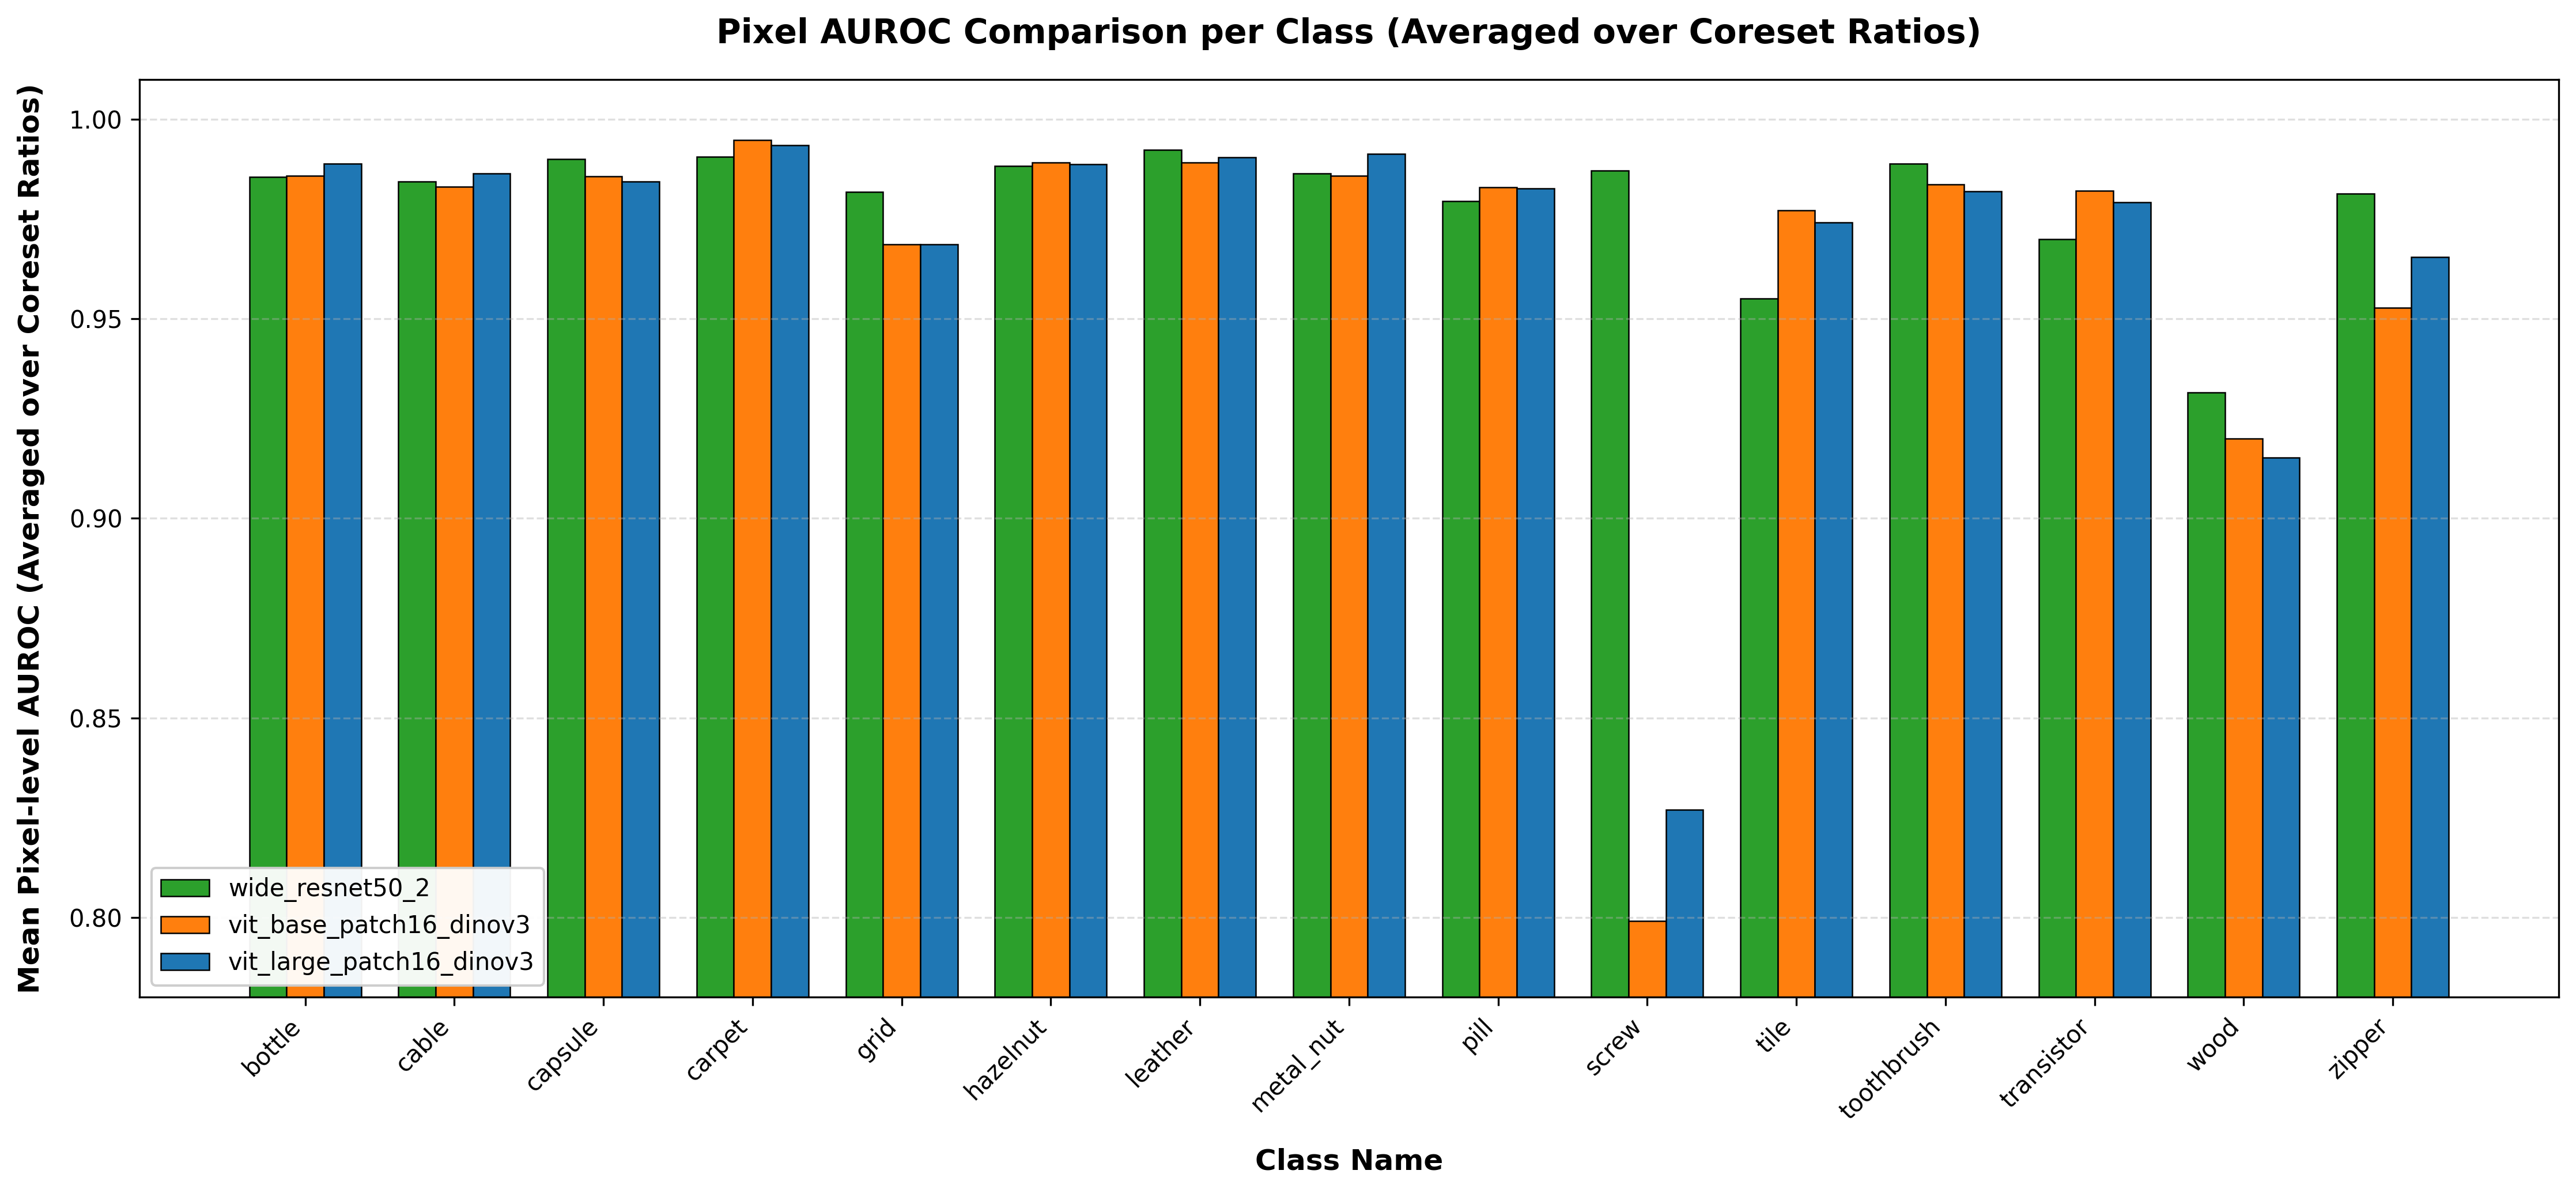

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate mean Pixel-level AUROC over all coreset ratios per Class and Backbone
grouped_class_pixel = df_filtered.groupby(['Clean_Category', 'Backbone'])['Pixel_AUROC'].mean().reset_index()

# Pivot data for plotting
pivot_class_pixel = grouped_class_pixel.pivot(index='Clean_Category', columns='Backbone', values='Pixel_AUROC')
pivot_class_pixel = pivot_class_pixel[backbone_order]

# Plotting grouped bar chart per class for Pixel AUROC
x = np.arange(len(unique_classes))
width = 0.25

colors = {
    'wide_resnet50_2': '#2ca02c',       # Green
    'vit_base_patch16_dinov3': '#ff7f0e', # Orange
    'vit_large_patch16_dinov3': '#1f77b4' # Blue
}

fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

for i, backbone in enumerate(backbone_order):
    rects = ax.bar(
        x + (i - 1) * width,
        pivot_class_pixel[backbone],
        width,
        label=backbone,
        color=colors[backbone],
        edgecolor='black',
        linewidth=0.6
    )

ax.set_xlabel('Class Name', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Mean Pixel-level AUROC (Averaged over Coreset Ratios)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Pixel AUROC Comparison per Class (Averaged over Coreset Ratios)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(unique_classes, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0.78, 1.01)  # Adjust limits to focus on the high performing range
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='lower left', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('class_pixel_auroc_comparison.png', dpi=300)
plt.show()

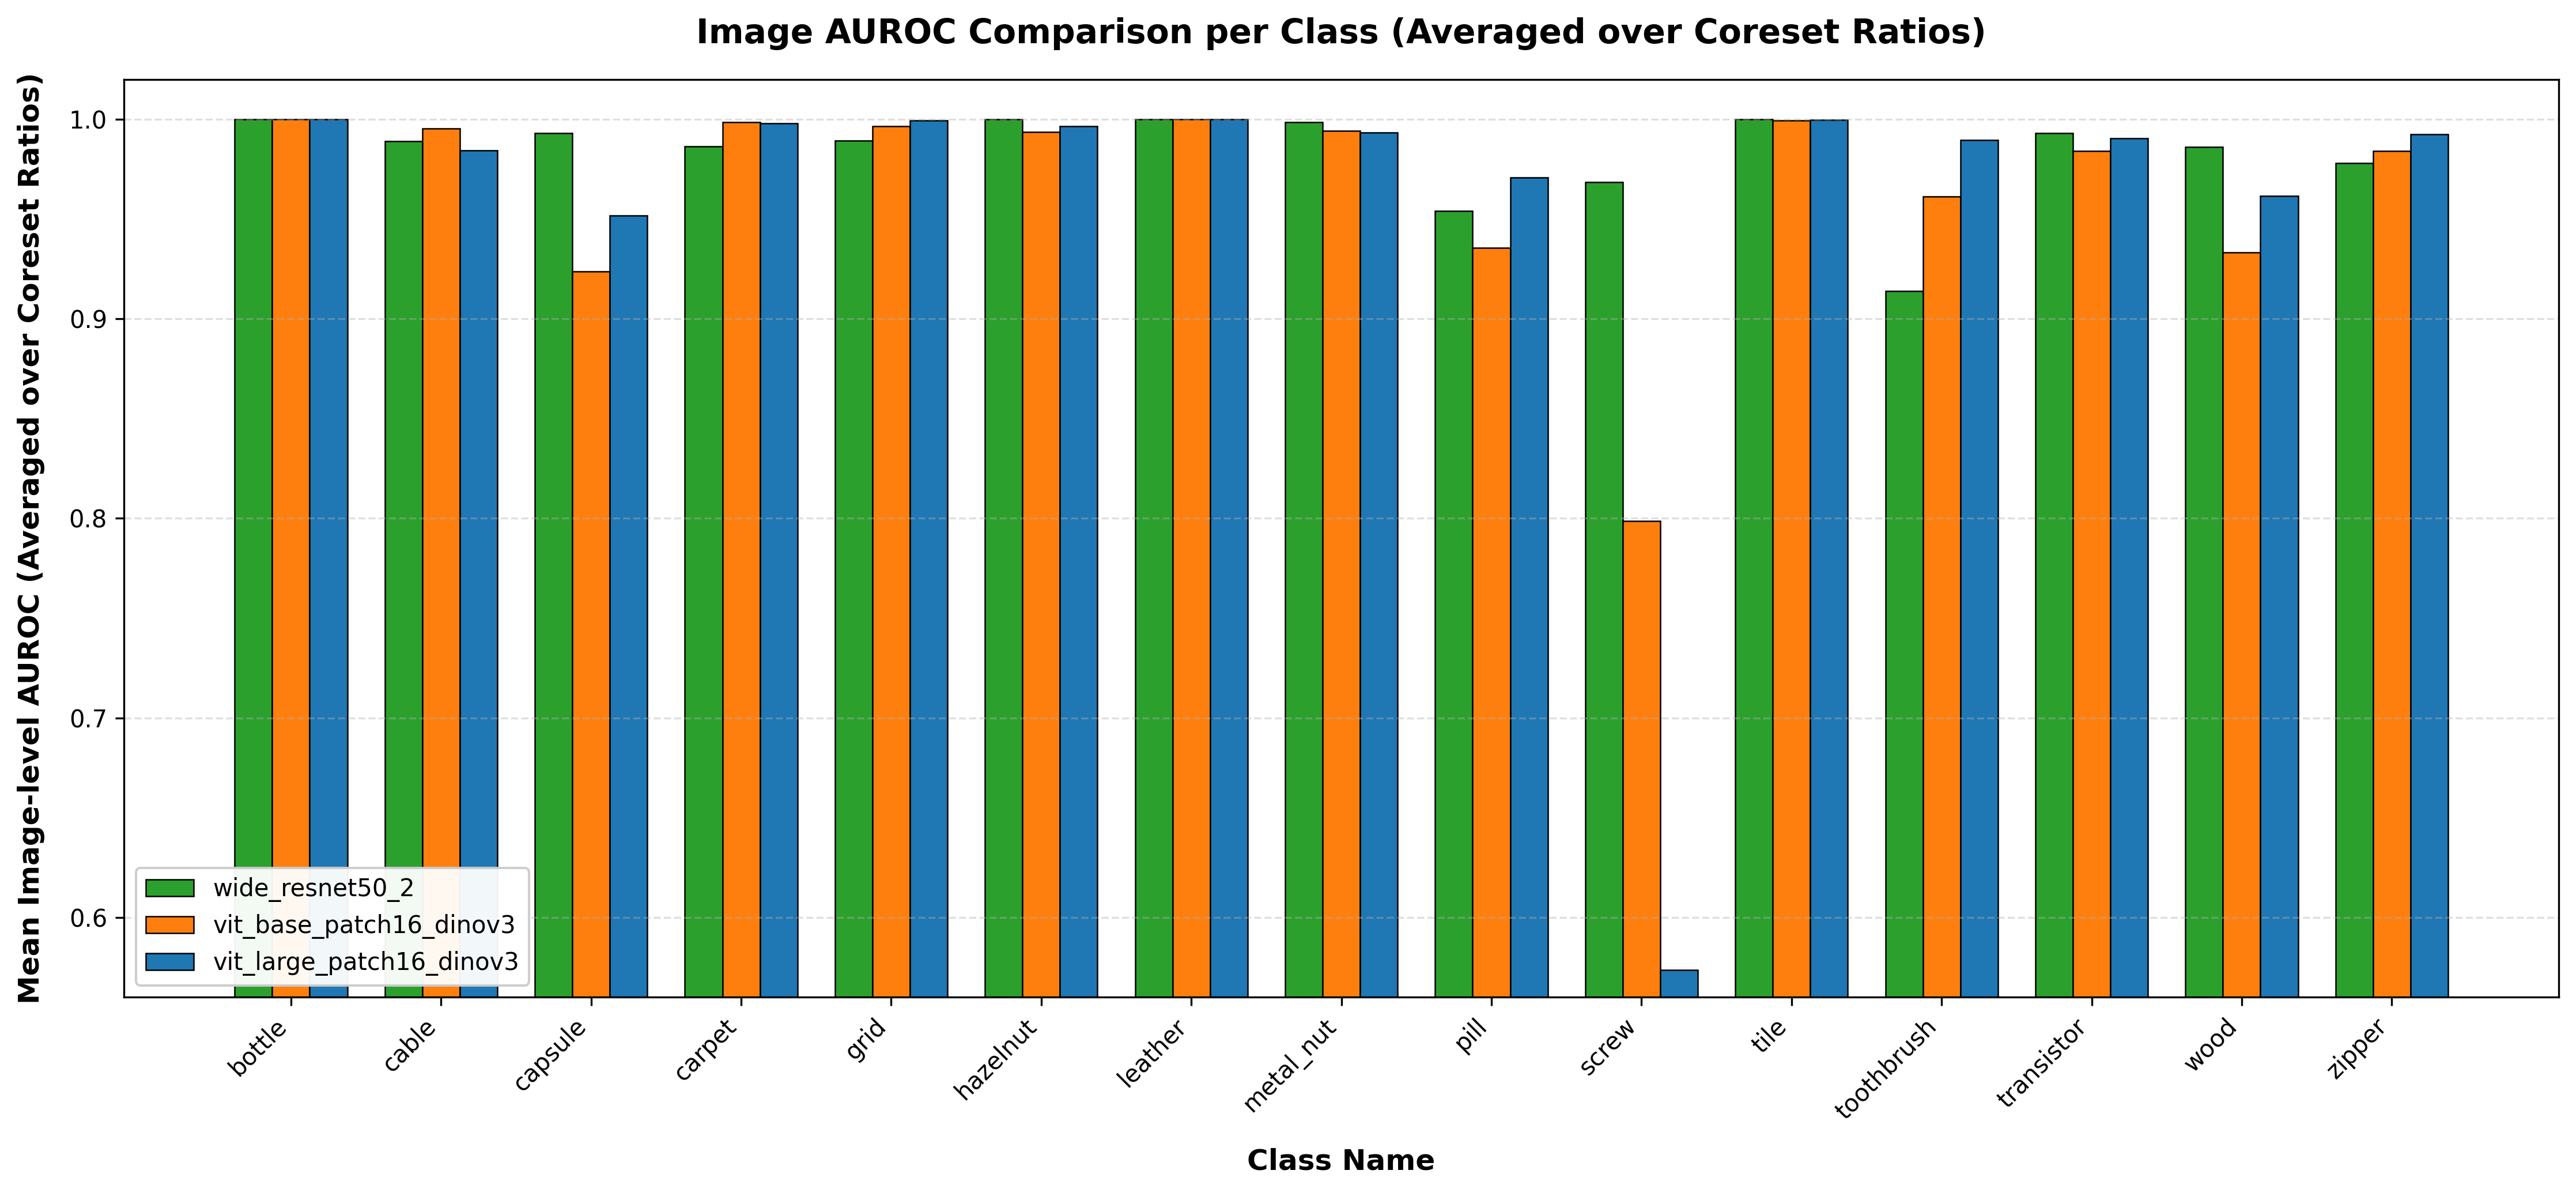

In [ ]:
# 5. Plotting grouped bar chart per class for Image AUROC
x = np.arange(len(unique_classes))
width = 0.25

colors = {
    'wide_resnet50_2': '#2ca02c',       # Green
    'vit_base_patch16_dinov3': '#ff7f0e', # Orange
    'vit_large_patch16_dinov3': '#1f77b4' # Blue
}

fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

for i, backbone in enumerate(backbone_order):
    rects = ax.bar(
        x + (i - 1) * width,
        pivot_class_auroc[backbone],
        width,
        label=backbone,
        color=colors[backbone],
        edgecolor='black',
        linewidth=0.6
    )

ax.set_xlabel('Class Name', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Mean Image-level AUROC (Averaged over Coreset Ratios)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Image AUROC Comparison per Class (Averaged over Coreset Ratios)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(unique_classes, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0.56, 1.02)  # Adjust limits dynamically depending on your data
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='lower left', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('class_image_auroc_comparison.png', dpi=300)
plt.show()

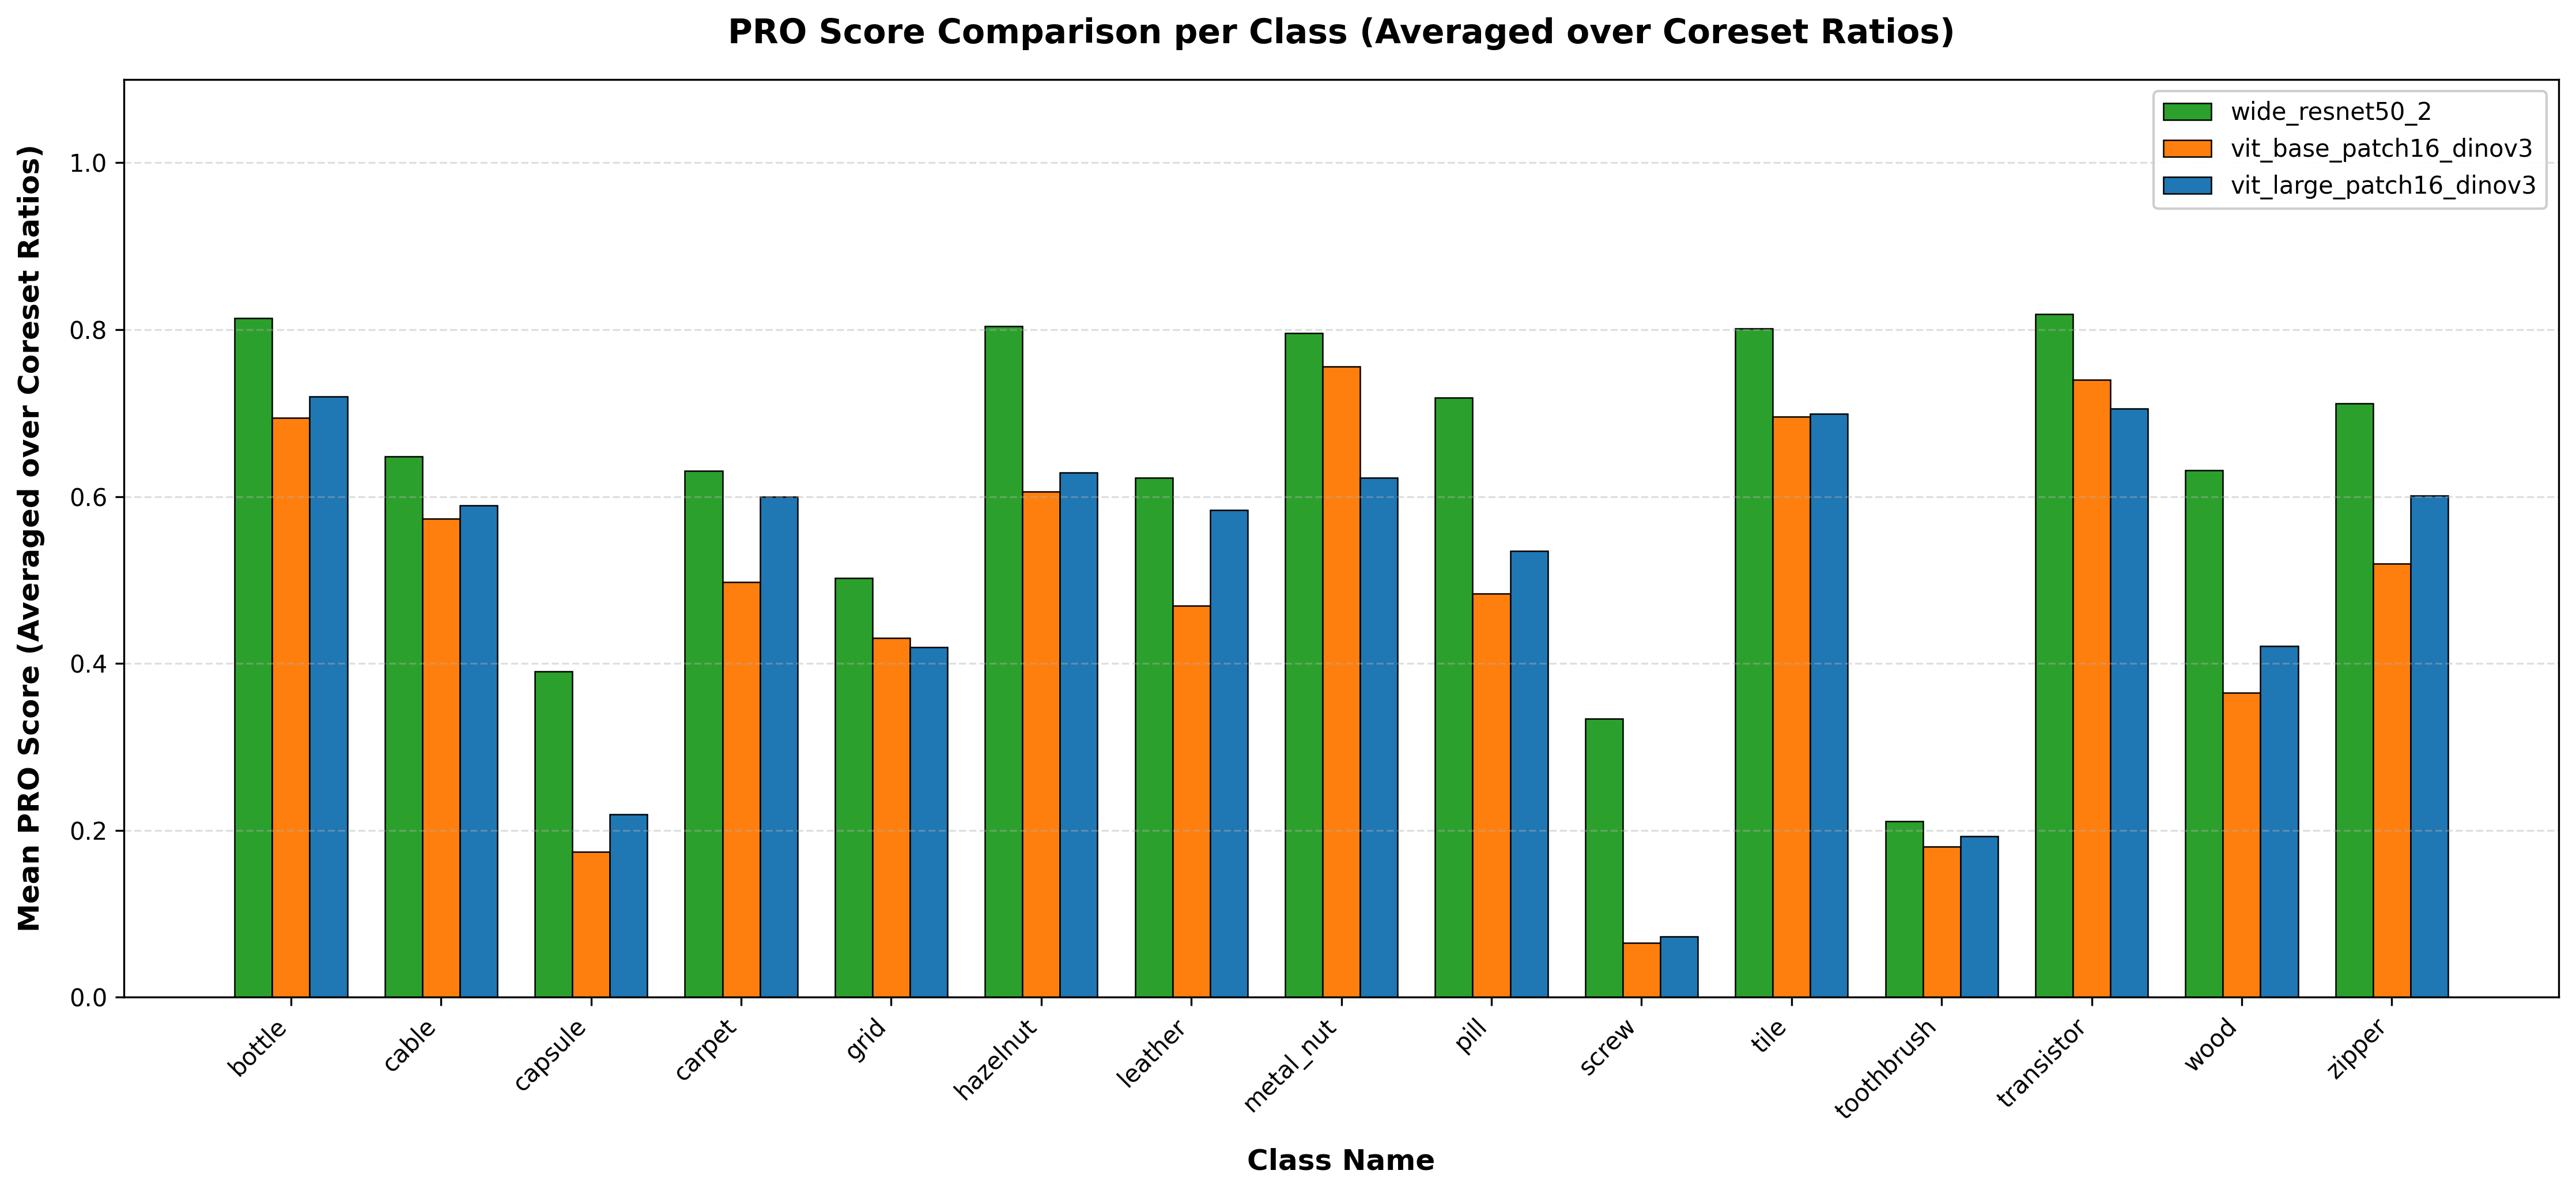

In [ ]:
# 6. Plotting grouped bar chart per class for PRO metric
fig, ax = plt.subplots(figsize=(15, 7), dpi=300)

for i, backbone in enumerate(backbone_order):
    rects = ax.bar(
        x + (i - 1) * width,
        pivot_class_pro[backbone],
        width,
        label=backbone,
        color=colors[backbone],
        edgecolor='black',
        linewidth=0.6
    )

ax.set_xlabel('Class Name', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Mean PRO Score (Averaged over Coreset Ratios)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('PRO Score Comparison per Class (Averaged over Coreset Ratios)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(unique_classes, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0.0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(loc='upper right', frameon=True, framealpha=0.95, fontsize=10)

plt.tight_layout()
plt.savefig('class_pro_comparison.png', dpi=300)
plt.show()

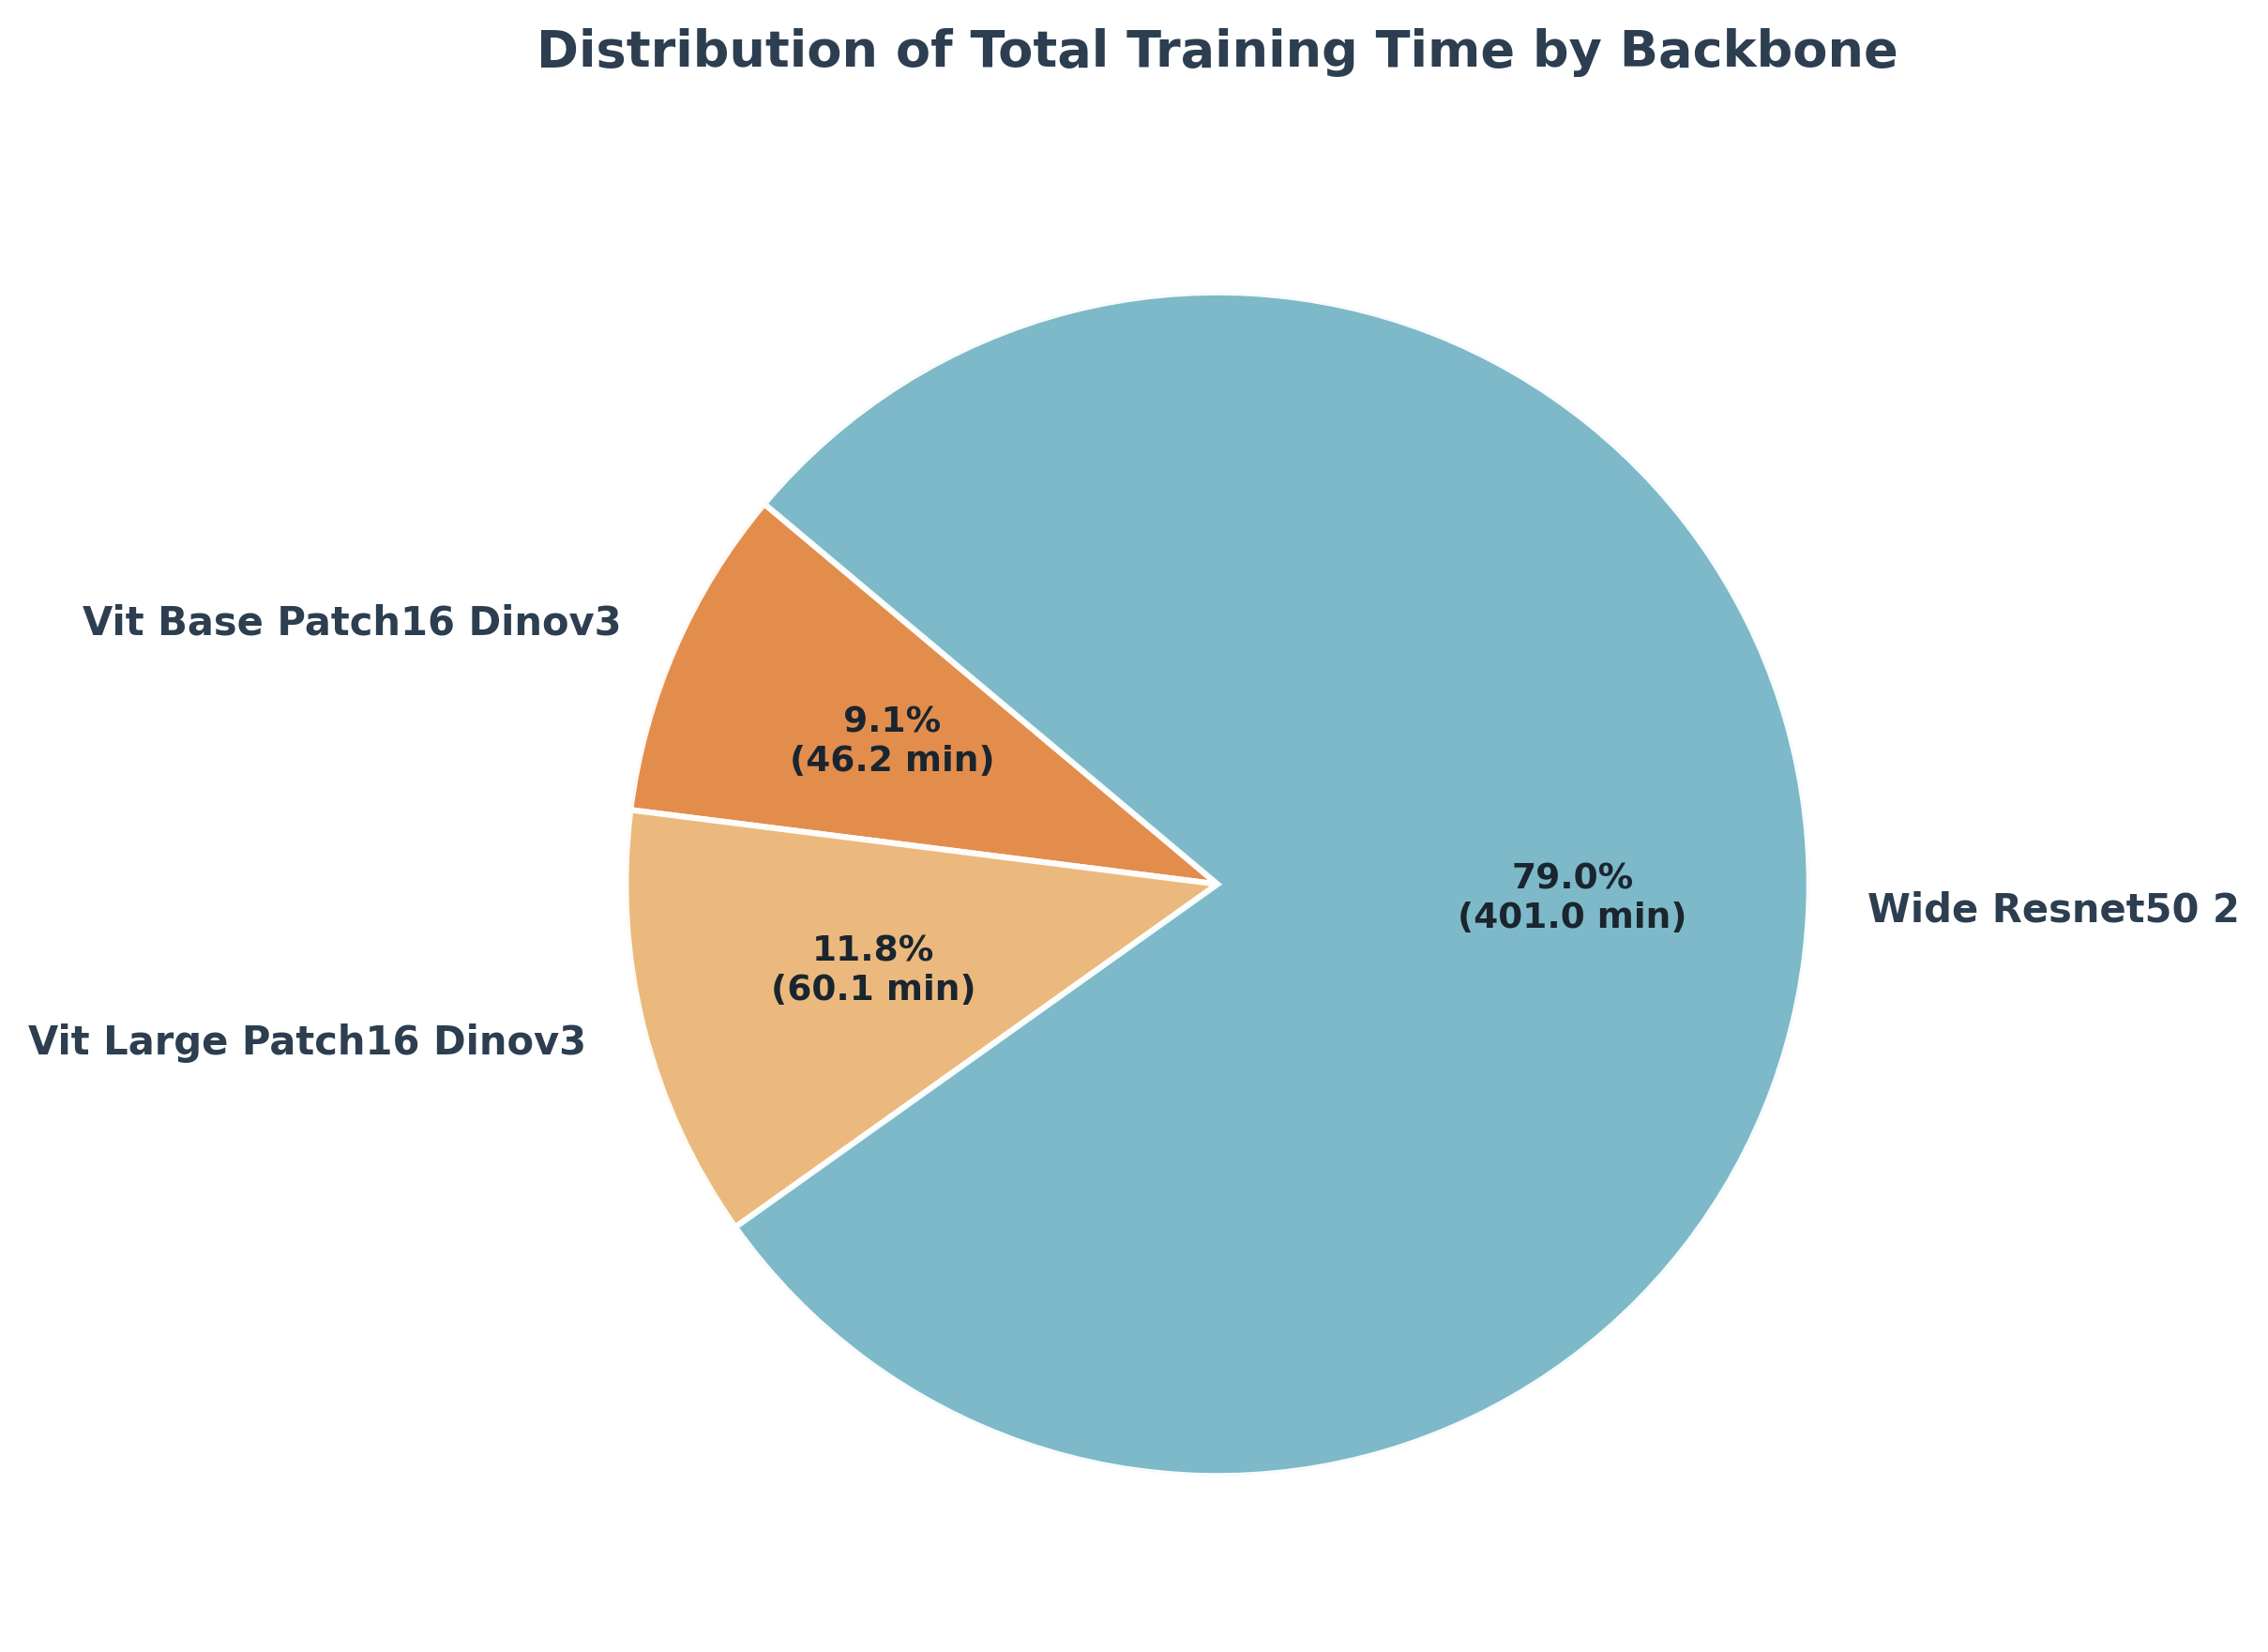

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load the experimental data
excel_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_vit_experiments_v3_1.xlsx")
df = pd.read_excel(excel_path)

# 2. Sum the training time in seconds by Backbone and convert to minutes
time_by_backbone = df.groupby('Backbone')['Training_Time_Sec'].sum() / 60.0

# 3. Create the pie chart
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

# Use a professional, warm, and natural earthy-sunset color palette
# These shades are organic, soft, and blend harmoniously
colors = [
    '#e28743',  # Warm Terracotta Orange
    '#eab676',  # Soft Sandy Amber
    '#76b5c5'   # Earthy Muted Teal
]

# Map backbones present in the data to colors safely
mapped_colors = [colors[i % len(colors)] for i in range(len(time_by_backbone))]

# Clean up labels for a more polished look
clean_labels = [
    label.replace('_', ' ').title() for label in time_by_backbone.index
]

# Plot pie chart
wedges, texts, autotexts = ax.pie(
    time_by_backbone,
    labels=clean_labels,
    autopct=lambda pct: f'{pct:.1f}%\n({pct*sum(time_by_backbone)/100:.1f} min)',
    startangle=140,
    colors=mapped_colors,
    textprops=dict(color="#2c3e50", fontsize=10, fontweight='semibold'),
    wedgeprops=dict(edgecolor='#ffffff', linewidth=1.5, alpha=0.95)
)

# Styling adjustments
plt.setp(autotexts, size=9, weight="bold", color="#1a252f")
ax.set_title("Distribution of Total Training Time by Backbone", fontsize=13, fontweight='bold', color="#2c3e50", pad=20)

plt.tight_layout()
plt.show()

# Hyperparamter Optimization

In [ ]:
!pip install --quiet optuna openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.4 MB/s eta 0:00:00


In [ ]:
import gc
import os
import shutil
import torch
import optuna
import datetime
import time
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

# Ensure PyTorch operations are optimized
torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive Safely and Configure Dataset Paths
drive.mount('/content/drive', force_remount=False)

drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_hyp_optim_vit_base_num_blocks.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
] # COMEÇAR COM SCREW PARA ACABAR O BASE
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# We will loop through each class individually
for category in ALL_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} =================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    def objective(trial):
        # Clean GPU memory before trial runs
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter Space: Single block from blocks.0 to blocks.11
        selected_block = trial.suggest_categorical(
            "selected_block",
            [f"blocks.{i}" for i in range(12)]
        )
        layers = [selected_block]

        # Fixed Configuration
        backbone = "vit_base_patch16_dinov3"
        coreset_ratio = 0.1
        knn_neighbors = 9

        # Custom Evaluator with requested metrics
        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model & Engine Setup
        model = Patchcore(
            backbone=backbone,
            layers=layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        engine = Engine(
            default_root_dir=f"./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        # 4. Training and Evaluation
        try:
            start_fit = time.perf_counter()
            engine.fit(datamodule=datamodule, model=model)
            fit_duration_min = round((time.perf_counter() - start_fit) / 60.0, 3)

            test_results = engine.test(datamodule=datamodule, model=model)[0]

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)

            # Estimate disk size of the memory bank
            memory_bank_size_mb = estimate_memory_bank_size(model)

            # Log values inside trial attributes for tracking
            trial.set_user_attr("AUPIMO", aupimo)
            trial.set_user_attr("Image_AUROC", image_auroc)
            trial.set_user_attr("Memory_Bank_MB", memory_bank_size_mb)
            trial.set_user_attr("Fit_Time_Min", fit_duration_min)

            # Save results to Excel Log
            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Layers_Used": selected_block,
                "Coreset_Ratio": coreset_ratio,
                "KNN": knn_neighbors,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Fit_Time_Min": fit_duration_min
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df

            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Block: {selected_block} | AUPRO: {aupro:.4f} | Fit Time: {fit_duration_min:.2f} min | Size: {memory_bank_size_mb:.2f} MB")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to error: {e}")
            return 0.0

    # 5. Initialize Optuna Study with 6 random startup trials
    sampler = optuna.samplers.TPESampler(n_startup_trials=6, seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)

    # Run optimization for 10 total trials for the current class
    print(f"Starting 10 Optuna Optimization trials for {category}...")
    study.optimize(objective, n_trials=10)

    # 6. Display Best Results for current class
    print(f"\n========== OPTIMIZATION COMPLETED FOR {category.upper()} ==========")
    print(f"Best Trial Number: {study.best_trial.number}")
    print(f"Best Target (AUPRO): {study.best_value:.4f}")
    print(f"Best Parameters: {study.best_params}")
    print(f"Best Trial AUPIMO: {study.best_trial.user_attrs.get('AUPIMO', 0.0):.4f}")
    print(f"Best Trial Fit Time: {study.best_trial.user_attrs.get('Fit_Time_Min', 0.0):.2f} min")
    print(f"Best Trial Memory Bank Size: {study.best_trial.user_attrs.get('Memory_Bank_MB', 0.0):.2f} MB\n")

In [ ]:
import gc
import os
import torch
import optuna
import datetime
import time
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive and set up logging
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_pooler_optimization_vit_base.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# We will loop through each class individually
for category in ALL_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} =================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    def objective(trial):
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter space for Feature Pooler
        pool_size = trial.suggest_categorical("pool_size", [1, 3, 5])

        # Other model configuration defaults matching your setup
        backbone = "vit_base_patch16_dinov3"
        layers = ["blocks.8"]
        coreset_ratio = 0.1
        knn_neighbors = 9

        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model instantiation
        model = Patchcore(
            backbone=backbone,
            layers=layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        # 4. Modify the feature_pooler within model.model
        if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
            padding = pool_size // 2
            model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
            print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride={1}, padding={padding})")
        else:
            print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

        # 5. Engine setup and run
        engine = Engine(
            default_root_dir="./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        try:
            start_fit = time.perf_counter()
            engine.fit(datamodule=datamodule, model=model)
            fit_duration_min = round((time.perf_counter() - start_fit) / 60.0, 3)

            test_results = engine.test(datamodule=datamodule, model=model)[0]

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)

            # Estimate disk size of the memory bank
            memory_bank_size_mb = estimate_memory_bank_size(model)

            # 6. Log configuration and scores
            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Pool_Size": pool_size,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Fit_Time_Min": fit_duration_min
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df
            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Pool Size: {pool_size} | AUPRO: {aupro:.4f} | Size: {memory_bank_size_mb:.2f} MB")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to: {e}")
            return 0.0

    # 7. Start the study for current class
    sampler = optuna.samplers.TPESampler(n_startup_trials=6, seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=6)

    print(f"\n========== OPTIMIZATION COMPLETED FOR {category.upper()} ==========")
    print(f"Best Pool Size: {study.best_params}")
    print(f"Best AUPRO Score: {study.best_value:.4f}\n")

### Dynamic Multi-Dimensional Optuna Optimization
This setup simultaneously optimizes:
1. **Pooling/Kernel Size** ( with size 1, 3, or 5).
2. **Number of Blocks to Extract** (between 1 and 3 layers).
3. **Layer Combinations** (dynamically selecting unique block IDs).

In [ ]:
import gc
import os
import torch
import optuna
import datetime
import time
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive and set up logging
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_multidim_optim_vit_large.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size()
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# Loop through each category to perform optimization
for category in TEXTURE_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} =================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    def objective(trial):
        # Clear GPU Memory
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter Space: Pool Size & Layers
        pool_size = trial.suggest_categorical("pool_size", [1, 3, 5])
        num_layers = trial.suggest_int("num_layers", 1, 3)

        # Dynamically select 'num_layers' unique block indices from blocks.0 to blocks.11
        available_blocks = [f"blocks.{i}" for i in range(24)]
        chosen_layers = []
        for i in range(num_layers):
            layer = trial.suggest_categorical(f"layer_selection_{i}", available_blocks)
            chosen_layers.append(layer)

        # Ensure unique block selection
        chosen_layers = list(sorted(list(set(chosen_layers))))

        # Base configuration
        backbone = "vit_large_patch16_dinov3"
        coreset_ratio = 0.1
        knn_neighbors = 9

        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model instantiation
        model = Patchcore(
            backbone=backbone,
            layers=chosen_layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        # 4. Modify the feature_pooler (retains AvgPool2d only)
        if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
            padding = pool_size // 2
            model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
            print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
        else:
            print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

        # 5. Engine Setup and Fit
        engine = Engine(
            default_root_dir="./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        try:
            start_fit = time.perf_counter()
            engine.fit(datamodule=datamodule, model=model)
            fit_duration_min = round((time.perf_counter() - start_fit) / 60.0, 3)

            test_results = engine.test(datamodule=datamodule, model=model)[0]

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)
            pixel_auroc = test_results.get("pixel_AUROC", 0.0)

            memory_bank_size_mb = estimate_memory_bank_size(model)

            # Log results inside trial attributes
            trial.set_user_attr("AUPIMO", aupimo)
            trial.set_user_attr("Image_AUROC", image_auroc)
            trial.set_user_attr("Pixel_AUROC", pixel_auroc)
            trial.set_user_attr("Memory_Bank_MB", memory_bank_size_mb)
            trial.set_user_attr("Fit_Time_Min", fit_duration_min)

            # 6. Save back to Persistent Excel Spreadsheet
            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Layers_Used": ", ".join(chosen_layers),
                "Pool_Size": pool_size,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Pixel_AUROC": round(float(pixel_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Fit_Time_Min": fit_duration_min
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df
            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Layers: {chosen_layers} | Pool Size: {pool_size} | AUPRO: {aupro:.4f} | Size: {memory_bank_size_mb:.2f} MB")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to: {e}")
            return 0.0

    # 7. Setup Optuna Study for current class
    sampler = optuna.samplers.TPESampler(n_startup_trials=20, seed=42, multivariate=True, gamma=0.15)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=15)

# Grid Search

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_large.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_large_patch16_dinov3"
CORESET_RATIO = 0.10
KNN_NEIGHBORS = 9
pool_size = 1

# User specified combinations of layers
layer_experiments = [
    ["blocks.1", "blocks.11", "blocks.21"],
    ["blocks.19", "blocks.20", "blocks.9"],
    ["blocks.10", "blocks.13", "blocks.6"],
    ["blocks.13", "blocks.8"]
]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for layers in layer_experiments:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # Modify the feature pooler as requested
    if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
        padding = pool_size // 2
        model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
        print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
    else:
        print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with layers {layers} and pool_size {pool_size}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", 0.0)
    pixel_auroc = test_results.get("pixel_AUROC", 0.0)
    aupro = test_results.get("AUPRO", 0.0)
    aupimo = test_results.get("AUPIMO", 0.0)
    memory_bank_size_mb = estimate_memory_bank_size(model)

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "AUPRO": round(float(aupro), 4),
        "AUPIMO": round(float(aupimo), 4),
        "Memory_Bank_MB": round(float(memory_bank_size_mb), 2)
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

    # Display current logged history
    print("\n========== EXPERIMENT LOG HISTORY ==========")
    print(updated_df.to_string(index=False))

# Grid Search V2

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base_v2.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
# OBJECT_CATEGORIES = [
#     "cable"
# ]
OBJECT_CATEGORIES = [
    "bottle", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]

TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = 0.10
KNN_NEIGHBORS = 9
pool_size = 1

# Dynamic combinations: ['blocks.0', 'blocks.1'] up to ['blocks.0', 'blocks.11']
layers_to_test = [["blocks.3", f"blocks.{i}"] for i in range(4, 12)]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for layers in layers_to_test:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
            # AUPIMO(fpr_bounds=(0.002, 1.0))
        ]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # Modify the feature pooler as requested
    if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
        padding = pool_size // 2
        model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
        print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
    else:
        print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with layers {layers} and pool_size {pool_size}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", 0.0)
    pixel_auroc = test_results.get("pixel_AUROC", 0.0)
    aupro = test_results.get("AUPRO", 0.0)
    aupimo = test_results.get("AUPIMO", 0.0)
    memory_bank_size_mb = estimate_memory_bank_size(model)

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "AUPRO": round(float(aupro), 4),
        "AUPIMO": round(float(aupimo), 4),
        "Memory_Bank_MB": round(float(memory_bank_size_mb), 2)
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

# Final Grid Search Base

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, PRO, AUPRO, AUPIMO

torch.set_float32_matmul_precision('high')

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_base.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = [0.01, 0.03, 0.05, 0.07]
KNN_NEIGHBORS = 9
pool_size = 1
layer_experiments = [["blocks.0", "blocks.9"], ["blocks.11"], ["blocks.0", "blocks.8"], ["blocks.0", "blocks.10"]]

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    for blocks in layer_experiments:
      gc.collect()
      torch.cuda.empty_cache()

      metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
      ]

      evaluator = Evaluator(test_metrics=metrics)

      # 3. DataModule Configuration
      datamodule = MVTecAD(
          root=drive_dataset_root,
          category=category,
          train_batch_size=32,
          eval_batch_size=32,
          num_workers=4,
      )

      # 4. PatchCore Model Configuration
      model = Patchcore(
          backbone=BACKBONE,
          layers=blocks,
          coreset_sampling_ratio=coreset_ratio,
          num_neighbors=KNN_NEIGHBORS,
          evaluator=evaluator,
      )

      # Apply Feature Pooler override
      if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
          padding = pool_size // 2
          model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
          print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
      else:
          print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

      # 5. Engine Setup
      engine = Engine(
          default_root_dir="./results",
          accelerator="gpu",
          devices=1,
          enable_progress_bar=False,
      )

      start_time = time.perf_counter()

      # 6. Fit and Test
      print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
      engine.fit(datamodule=datamodule, model=model)

      training_duration = round(time.perf_counter() - start_time, 2)
      print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

      print("Running test evaluation...")
      test_results_raw = engine.test(datamodule=datamodule, model=model)

      test_results = test_results_raw[0] if test_results_raw else {}

      # 7. Extract Metric Scores
      image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
      pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
      aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
      aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))

      new_record = {
          "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
          "Training_Time_Sec": training_duration,
          "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
          "Backbone": BACKBONE,
          "Layers_Used": ", ".join(blocks),
          "Pool_Size": pool_size,
          "Coreset_Ratio": coreset_ratio,
          "KNN": KNN_NEIGHBORS,
          "Image_AUROC": round(float(image_auroc), 4),
          "Pixel_AUROC": round(float(pixel_auroc), 4),
          "AUPRO": round(float(aupro), 4),
          "AUPIMO": round(float(aupimo), 4),
      }

      new_df = pd.DataFrame([new_record])

      # 8. Append to Persistent Excel Spreadsheet
      if excel_log_path.exists():
          existing_df = pd.read_excel(excel_log_path)
          updated_df = pd.concat([existing_df, new_df], ignore_index=True)
      else:
          updated_df = new_df

      updated_df.to_excel(excel_log_path, index=False)
      print(f"\nExperiment successfully logged to: {excel_log_path}")

      # Display current logged history
      print("\n========== EXPERIMENT LOG HISTORY ==========")
      print(updated_df.to_string(index=False))

# Download Dataset

In [ ]:
from google.colab import drive
from pathlib import Path
from anomalib.data import MVTecAD

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the destination directory inside your Drive
drive_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
drive_root.mkdir(parents=True, exist_ok=True)

# 3. Instantiate datamodule pointing to Drive
datamodule = MVTecAD(
    root=drive_root,
    category="bottle",
)

# 4. Trigger the official download and extraction routine
print("Downloading and extracting to Google Drive...")
datamodule.prepare_data()
print("Download complete!")